*[cell 0]*

# Replication figures

Draws every figure of the manuscript and of the final report from the pipeline's exports (pinned in `[cell 1]`), at
its printed size, and writes each as `figures/pub_figures/<main_text | supplement>/<name>.png` with a provenance
sidecar `<name>.json` (every file the figure is drawn from, including the selection files and run logs that decide
what it shows, with their sizes, SHA-256 and times; the pins; the time of drawing). It
computes no statistic. Run it after the LVL2 runs and before the final report, which links the figures and checks
their sidecars.

**Conditions.** The manuscript calls the two conditions cohorts: T2 = Cohort A (CA), T3 = Cohort B (CB). This notebook
is the one that prints CA and CB (`COHORT`, `[cell 1]`); the code, file names, exports and the final report keep T2
and T3.

Before drawing, `[cell 1]` stops unless the pins form one calibrated lineage: the LVL_1 handoff's configuration
equals the LVL1 selection's `LVL_1_CONFIG_full`, and every run's recorded LVL_2 configuration the LVL2 selection's
`LVL_2_CONFIG_full` (every key but `save_figures`, which writes figures only, and the runs' conditions, which are
checked against `RUN_TAGS`); `lvl1.py` has the LVL1 sweep's fingerprint, and `lvl2.py` the LVL2 sweep's, or every
line on which it differs from the sweep's script copy is a comment or blank line or a line setting a selected
`LVL_2_CONFIG` knob in NOTEBOOK CELL 28, and the check lists each differing cell and the rule that admitted its
lines; the LVL2 sweep and every run use the LVL1-selected detector; both sweeps were calibrated on T2; the LVL2
sweep and every run were made on the pinned LVL_1 handoff, and the LVL_1 handoff and the LVL1 sweep on the pinned
LVL_0 handoff.

| Figure | File | Inputs |
|---|---|---|
| Decay curves and log-RT distributions (main text; raw and Box-Cox in the supplement) | `main_text/fig_decay_curves.png`, `supplement/fig_decay_curves_{raw,boxcox}.png` | LVL0 notebook: decay fits and curves; the LVL_0 handoff |
| LVL1 calibration and two segmented sessions | `main_text/fig_lvl1_calibration.png` | LVL1 sweep report (configurations, best configurations); LVL1 notebook (H1 tests); the LVL_1 handoff |
| RT, RT variance and entropy distributions | `supplement/fig_feature_distributions.png` | LVL1 notebook (session features); the LVL_0 handoff |
| Age associations of the features | `supplement/fig_age_by_feature.png` | LVL1 notebook (age check) |
| Dose-response of the alpha gain across the LVL2 sweep | `supplement/fig_dose_response.png` | LVL2 sweep report (dose points, fits, picks; the stars from its primary dose contrasts) |
| GMM posterior P(inattentive) per block | `supplement/fig_gmm_posterior.png` | LVL2 runs (posterior exports) |
| One participant's sessions: features, every detector's blocks, the flagged blocks (ids in `PARTICIPANT_FIGURES`) | `supplement/participants/fig_participant_<id>.png` | the LVL_1 handoff; the participant's LVL2 run (annotated export) |

Not produced by code (external assets of the manuscript): `task_example_long.png` (the rating task) and
`matrix_example3.png` (the block-matrix illustration).

In [1]:
# [cell 1]
# ===== INPUTS: set these before running =====
LVL0_HANDOFF = "lv0_out_20261106_180438.csv"            # LVL_0 handoff in LVL_OUTS
LVL1_HANDOFF = "lv1_out_20261106_190046"                # LVL_1 handoff prefix in LVL_OUTS
LVL1_SWEEP   = "_sweep_lvl1_T2"                         # LVL_1 T2 calibration sweep (its report's exports)
LVL2_SWEEP   = "_sweep_lvl2_T2_PELT_Attention_comp"        # LVL_2 T2 calibration sweep (its report's exports)
RUN_TAGS = {"T2":   "lv2_out_PELT_Attention_comp_T2_20261107_192158",
            "T3":   "lv2_out_PELT_Attention_comp_T3_20261107_192158"}
# [pooled pathway: practical-application folder] the pooled T2 + T3 run
#> RUN_TAGS["both"] = "lv2_out_PELT_Attention_comp_T2+T3_20261103_224209"
MOSAIC_PARTICIPANTS = [4064, 1051]                      # LVL1 calibration figure: one T2 and one T3 participant
PARTICIPANT_FIGURES = [4064, 1051]                      # participant session figures (supplement/participants): any analysed ids

import ast, difflib, hashlib, json, re, time
from pathlib import Path
import numpy as np
import pandas as pd
from scipy import stats
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
from matplotlib.lines import Line2D
from matplotlib.collections import PathCollection

# ---- locations: everything is inside /home/sjsuss626/EMST_files/sjs_dissertation ----------------
LVL_OUTS = Path("/home/sjsuss626/EMST_files/sjs_dissertation/dervatives/dynamic_qc/lvl_outs")
FIG_DIR  = Path("/home/sjsuss626/EMST_files/sjs_dissertation/dervatives/dynamic_qc/figures/pub_figures")
SWEEPS_DIR = Path("/home/sjsuss626/EMST_files/sjs_dissertation/dervatives/dynamic_qc/sweeps")
CODE_DIR = Path("/home/sjsuss626/EMST_files/sjs_dissertation/code/cpd_and_blk_rep_anaylsis")
LV0 = LVL_OUTS / LVL0_HANDOFF.removesuffix(".csv")
HANDOFF = LVL_OUTS / LVL1_HANDOFF
RUN = {k: LVL_OUTS / v for k, v in RUN_TAGS.items()}
_need = ([Path(f"{LV0}.csv"), Path(f"{LV0}_parameters.json"), Path(f"{LV0}_decay_fits.csv"),
          Path(f"{LV0}_decay_curves.csv"), Path(f"{HANDOFF}_features.csv"), Path(f"{HANDOFF}_meta.json"),
          Path(f"{HANDOFF}_report_session_features.csv"), Path(f"{HANDOFF}_report_age_participants.csv"),
          Path(f"{HANDOFF}_report_age_continuous.csv"), Path(f"{HANDOFF}_report_age_groups.csv"),
          Path(f"{HANDOFF}_h1_ranks.csv"),
          LVL_OUTS / f"{LVL1_SWEEP}_selection.json", LVL_OUTS / f"{LVL2_SWEEP}_selection.json",
          SWEEPS_DIR / LVL1_SWEEP / "_provenance.json", SWEEPS_DIR / LVL2_SWEEP / "_provenance.json",
          CODE_DIR / "lvl1.py", CODE_DIR / "lvl2.py"]
         + [LVL_OUTS / f"{LVL1_SWEEP}_report_{k}.csv" for k in ("configs", "best_eta", "best_corr")]
         + [LVL_OUTS / f"{LVL2_SWEEP}_report_{k}.csv" for k in ("dose_points", "dose_fits", "dose_picks",
                                                                  "dose_contrasts", "dsc_configs", "dsc_picks")]
         + [Path(f"{p}_post_replicates.npz") for p in RUN.values()]
         + [Path(f"{p}_{x}.json") for p in RUN.values() for x in ("config", "parameters")]
         + [Path(f"{RUN[k]}_{x}.csv") for k in ("T2", "T3") for x in ("annotated", "post_dsc_designs", "step9_design_summary",
                                                                     "step9_design_tests", "step8_multimetric")])
_missing = [str(p) for p in _need if not p.exists()]
if _missing:
    raise SystemExit("inputs not found (run the stage that writes each one first; README, execution order):\n  "
                     + "\n  ".join(_missing))
SEL1 = json.load(open(LVL_OUTS / f"{LVL1_SWEEP}_selection.json"))
SEL2 = json.load(open(LVL_OUTS / f"{LVL2_SWEEP}_selection.json"))
META = json.load(open(f"{HANDOFF}_meta.json"))
_l1cfg = META["lvl1_config"]

# ---- lineage: nothing is drawn unless the pins are one calibrated chain ----------------------------------------
# (a) the LVL_1 handoff's configuration (_meta.json lvl1_config) = the LVL1 selection's LVL_1_CONFIG_full on every
#     key but EXEMPT_L1; (b) each run's recorded LVL_2 configuration (_parameters.json "parameters" and the
#     LVL_2_CONFIG keys of _config.json) = the LVL2 selection's LVL_2_CONFIG_full on every key both record but
#     EXEMPT_L2; (c) lvl1.py has the LVL1 sweep's fingerprint, and lvl2.py the LVL2 sweep's or every line on which it
#     differs from the sweep's script copy is admitted by a rule of lvl2_script_diff (comment or blank lines, the
#     selection's LVL_2_CONFIG knobs in NOTEBOOK CELL 28); (d) the LVL2 sweep and every run use the LVL1-selected
#     detector; (e) both sweeps were calibrated on T2.
#     Handoffs: the LVL_1 handoff and the LVL1 sweep were made on LVL0_HANDOFF, the LVL2 sweep and every run on
#     LVL1_HANDOFF (and the runs on LVL0_HANDOFF), and each run's conditions are its RUN_TAGS key's.
EXEMPT_L1 = {"save_figures": "writes figures only", "n_jobs": "number of parallel workers",
             "parallel_verbose": "log verbosity"}
EXEMPT_L2 = {"save_figures": "writes figures only", "conditions": "run design, checked against RUN_TAGS"}
RUN_CONDITIONS = {"T2": ["T2"], "T3": ["T3"]}
# [pooled pathway: practical-application folder] the pooled run's conditions
#> RUN_CONDITIONS["both"] = ["T2", "T3"]


def _fp(p):
    """A level script's fingerprint: the first 16 hex digits of the SHA-256 of its bytes."""
    return hashlib.sha256(Path(p).read_bytes()).hexdigest()[:16]


def _plain(v):
    """A configuration value as JSON data (tuples as lists)."""
    if isinstance(v, (list, tuple)):
        return [_plain(x) for x in v]
    if isinstance(v, dict):
        return {str(k): _plain(x) for k, x in v.items()}
    return v


def _logged(s):
    """A value of the LVL_1 run log (lvl1_config holds str() of each value) as JSON data."""
    if not isinstance(s, str):
        return _plain(s)
    try:
        return _plain(ast.literal_eval(s))
    except (ValueError, SyntaxError, TypeError):
        return s


def _same(a, b):
    """Equal configuration values: a bool equals only a bool, numbers compare by value."""
    if isinstance(a, bool) or isinstance(b, bool):
        return type(a) is type(b) and a == b
    if isinstance(a, list) and isinstance(b, list):
        return len(a) == len(b) and all(map(_same, a, b))
    if isinstance(a, dict) and isinstance(b, dict):
        return a.keys() == b.keys() and all(_same(a[k], b[k]) for k in a)
    return a == b


# ---- check (c) for lvl2.py: the lines on which it may differ from the LVL2 sweep's script copy ----------------------
# A line that differs (difflib, on either side) is admitted by (i) when it is a comment or blank line and by (ii) when
# it sets one of the selection's LVL_2_CONFIG knobs in NOTEBOOK CELL 28 (the lines README step 10 writes). A line no
# rule admits fails the check.
import io, tokenize
LVL2_DIFF_RULES = {"(i)": "comment or blank line",
                   "(ii)": "line setting a selected LVL_2_CONFIG knob in NOTEBOOK CELL 28"}


def lvl2_script_diff(ref, cur, knobs):
    """The lines that differ between the LVL2 sweep's script copy (ref) and lvl2.py (cur), both sides, sorted by the rule
    of check (c) that admits each: ({NOTEBOOK CELL: {rule: number of lines}}, [the lines no rule admits])."""
    sides = []
    for path in (ref, cur):
        text = Path(path).read_text()
        code = set()                # line numbers (from 1) holding a token other than a comment or a line break
        for t in tokenize.generate_tokens(io.StringIO(text).readline):
            if t.type not in (tokenize.COMMENT, tokenize.NL, tokenize.NEWLINE, tokenize.INDENT, tokenize.DEDENT,
                              tokenize.ENDMARKER):
                code.update(range(t.start[0], t.end[0] + 1))
        lines, cells, c = text.splitlines(), [], None
        for ln in lines:
            m = re.match(r"# =+ NOTEBOOK CELL (\d+) =+\s*$", ln)
            c = int(m.group(1)) if m else c
            cells.append(c)
        sides.append((lines, cells, code))
    admitted, bad = {}, []
    for op, i1, i2, j1, j2 in difflib.SequenceMatcher(None, sides[0][0], sides[1][0], autojunk=False).get_opcodes():
        if op == "equal":
            continue
        for name, (lines, cells, code), rows in (("script copy", sides[0], range(i1, i2)),
                                                 ("lvl2.py", sides[1], range(j1, j2))):
            for i in rows:
                key = re.match(r'\s*"(\w+)"\s*:', lines[i])
                rule = ("(i)" if i + 1 not in code else
                        "(ii)" if cells[i] == 28 and key and key.group(1) in knobs else None)
                if rule is None:
                    bad.append(f"{name} line {i + 1} (NOTEBOOK CELL {cells[i]}) is admitted by no rule of check (c): "
                               f"{lines[i].strip()[:70]}")
                else:
                    admitted.setdefault(cells[i], {}).setdefault(rule, 0)
                    admitted[cells[i]][rule] += 1
    return admitted, bad


def lvl2_diff_text(admitted):
    """Check (c)'s detail: every NOTEBOOK CELL with differing lines and the number of lines each rule admitted there."""
    parts = []
    for c in sorted(admitted, key=lambda c: -1 if c is None else c):
        where = "the script's header" if c is None else f"NOTEBOOK CELL {c}"
        parts.append(f"{where}: " + ", ".join(f"{r} {admitted[c][r]}" for r in LVL2_DIFF_RULES if r in admitted[c]))
    rules = "; ".join(f"{r} {txt}" for r, txt in LVL2_DIFF_RULES.items())
    return "; ".join(parts) + f" [lines per rule: {rules}]"


def _lineage(name, problems, detail):
    """One lineage check: passed when it found no problems."""
    (_bad if problems else LINEAGE).append(f"{name}: {detail}" + ("".join(f"\n      {p}" for p in problems)))


_absent = [f"{s}_selection.json: {k}" for s, sel, lvl in ((LVL1_SWEEP, SEL1, 1), (LVL2_SWEEP, SEL2, 2))
           for k in ("script_copy", f"LVL_{lvl}_CONFIG_full") if k not in sel]
if _absent:
    raise SystemExit("the sweep selections lack " + ", ".join(_absent) + " (rerun LVL1_sweep_report and "
                     "LVL2_sweep_report)")
PROV = {s: json.load(open(SWEEPS_DIR / s / "_provenance.json")) for s in (LVL1_SWEEP, LVL2_SWEEP)}
RUN_CONFIG = {k: json.load(open(f"{p}_config.json")) for k, p in RUN.items()}
RUN_PARAMS = {k: json.load(open(f"{p}_parameters.json"))["parameters"] for k, p in RUN.items()}
LINEAGE, _bad = [], []
_FULL1, _FULL2 = SEL1["LVL_1_CONFIG_full"], SEL2["LVL_2_CONFIG_full"]
_KNOBS2 = {k: v for fam in SEL2["families"].values() for k, v in fam["LVL_2_CONFIG"].items()}
_FP1, _FP2 = PROV[LVL1_SWEEP]["pipeline_fingerprint"], PROV[LVL2_SWEEP]["pipeline_fingerprint"]
_exempt = lambda d: "; ".join(f"{k}: {why}" for k, why in d.items())
# (a) LVL_1 configuration
_keys = sorted((set(_FULL1) | set(_l1cfg)) - set(EXEMPT_L1))
_d = [f"{k}: handoff {_l1cfg.get(k, '<absent>')}, selection {_FULL1.get(k, '<absent>')}" for k in _keys
      if k not in _FULL1 or k not in _l1cfg or not _same(_plain(_FULL1[k]), _logged(_l1cfg[k]))]
_d += [f"{k}: the selection's value {v!r} is not its LVL_1_CONFIG_full value" for k, v in SEL1["LVL_1_CONFIG"].items()
       if not _same(_plain(_FULL1.get(k)), _plain(v))]
_lineage("(a) LVL_1 configuration", _d, f"{HANDOFF.name}_meta.json lvl1_config vs the LVL1 selection's "
         f"LVL_1_CONFIG_full, {len(_keys)} keys (exempt, they cannot change a result: {_exempt(EXEMPT_L1)})")
# (b) LVL_2 configuration
_d = [f"{k}: the selection's value {v!r} is not its LVL_2_CONFIG_full value" for k, v in _KNOBS2.items()
      if not _same(_plain(_FULL2.get(k)), _plain(v))]
_n, _unrec = [], []
for r, p in RUN.items():
    for src, rec in (("_parameters.json", RUN_PARAMS[r]), ("_config.json", RUN_CONFIG[r])):
        _keys = sorted((set(rec) & set(_FULL2)) - set(EXEMPT_L2))
        _n.append(f"{r} {src} {len(_keys)}")
        _d += [f"{p.name}{src} {k}: run {rec[k]!r}, selection {_FULL2[k]!r}" for k in _keys
               if not _same(_plain(rec[k]), _plain(_FULL2[k]))]
    _unrec += [f"{r}: {k}" for k in sorted(set(_FULL2) - set(RUN_PARAMS[r]) - set(RUN_CONFIG[r]) - set(EXEMPT_L2))]
_lineage("(b) LVL_2 configuration", _d, "each run's recorded LVL_2 configuration vs the LVL2 selection's "
         f"LVL_2_CONFIG_full, every key both record ({', '.join(_n)}; exempt: {_exempt(EXEMPT_L2)}; not recorded "
         f"by a run, so not compared: {', '.join(_unrec) or 'none'})")
# (c) code
_d, _copy_ok = [], {}
for s, sel in ((LVL1_SWEEP, SEL1), (LVL2_SWEEP, SEL2)):
    if sel["pipeline_fingerprint"] != PROV[s]["pipeline_fingerprint"]:
        _d.append(f"{s}_selection.json fingerprint {sel['pipeline_fingerprint']} is not its sweep's "
                  f"({PROV[s]['pipeline_fingerprint']}, _provenance.json)")
    _copy_ok[s] = Path(sel["script_copy"]).is_file() and _fp(sel["script_copy"]) == PROV[s]["pipeline_fingerprint"]
    if not _copy_ok[s]:
        _d.append(f"the selection's script_copy {sel['script_copy']} is missing or not the script {s} ran")
FP = {f"lvl{i}.py": _fp(CODE_DIR / f"lvl{i}.py") for i in (1, 2)}
if FP["lvl1.py"] != _FP1:
    _d.append(f"lvl1.py {FP['lvl1.py']} is not the script the LVL1 sweep ran ({_FP1})")
_adm, _dl = {}, []                      # lvl2.py vs the sweep's script copy: the admitted lines by cell; the others
if FP["lvl2.py"] != _FP2 and _copy_ok[LVL2_SWEEP]:
    _adm, _dl = lvl2_script_diff(SEL2["script_copy"], CODE_DIR / "lvl2.py", _KNOBS2)
_lineage("(c) code", _d + _dl, f"lvl1.py {FP['lvl1.py']} vs the LVL1 sweep's {_FP1}; lvl2.py {FP['lvl2.py']} vs "
         f"the LVL2 sweep's {_FP2}" + (f"; lines that differ from the sweep's script copy, by NOTEBOOK CELL and the "
                                        f"rule admitting them: {lvl2_diff_text(_adm)}" if _adm else ""))
# (d) detector
_d = [f"{n}: {v}" for n, v in [(f"{LVL2_SWEEP}_selection.json analysis_method", SEL2.get("analysis_method"))]
      + [(f"{RUN[r].name}{src} analysis_method", rec.get("analysis_method")) for r in RUN
         for src, rec in (("_config.json", RUN_CONFIG[r]), ("_parameters.json", RUN_PARAMS[r]))]
      if v != SEL1["detector"]]
_lineage("(d) detector", _d, f"the LVL1 selection's detector {SEL1['detector']} vs the LVL2 selection's and every "
         "run's analysis_method")
# (e) calibration
_d = [f"{s}_selection.json condition {sel.get('condition')!r}" for s, sel in ((LVL1_SWEEP, SEL1), (LVL2_SWEEP, SEL2))
      if sel.get("condition") != "T2"]
_lineage("(e) calibration", _d, "both selections' condition = T2")
# handoffs
_l0 = LVL0_HANDOFF.removesuffix(".csv")
_made = ([(f"{HANDOFF.name}_meta.json lvl0_input", META.get("lvl0_input"), _l0),
          (f"{LVL1_SWEEP}_selection.json lvl0_input", SEL1.get("lvl0_input"), _l0),
          (f"{LVL1_SWEEP}/_provenance.json lvl0_input", PROV[LVL1_SWEEP].get("lvl0_input"), _l0),
          (f"{LVL2_SWEEP}_selection.json lvl1_input", SEL2.get("lvl1_input"), LVL1_HANDOFF),
          (f"{LVL2_SWEEP}/_provenance.json lvl1_input", PROV[LVL2_SWEEP].get("lvl1_input"), LVL1_HANDOFF)]
         + [(f"{RUN[r].name}_config.json {k}", RUN_CONFIG[r].get(k), pin) for r in RUN
            for k, pin in (("lvl1_input", LVL1_HANDOFF), ("lvl0_input", _l0))])
_d = [f"{n}: {v}" for n, v, pin in _made if str(v).removesuffix(".csv") != pin]
_d += [f"{RUN[r].name}_parameters.json conditions {RUN_PARAMS[r].get('conditions')} (RUN_TAGS key {r!r})"
       for r in RUN if RUN_PARAMS[r].get("conditions") != RUN_CONDITIONS.get(r)]
_lineage("handoffs", _d, f"the LVL_1 handoff and the LVL1 sweep vs {_l0}; the LVL2 sweep and every run vs "
         f"{LVL1_HANDOFF} (the runs also vs {_l0}); each run's conditions vs its RUN_TAGS key")
if _bad:
    raise SystemExit("lineage check failed (nothing drawn):\n  " + "\n  ".join(_bad))
print("lineage checks passed:\n  " + "\n  ".join(LINEAGE))
P0 = json.load(open(f"{LV0}_parameters.json"))["parameters"]
FAM_LABEL = {"cluster": "k-means", "mixture_gmm": "GMM"}
COHORT = {"T2": "CA", "T3": "CB"}                   # the conditions as the figures name them (cohort A, cohort B)
PICKS = {f"{FAM_LABEL[f]} ({d['k']})": (d["config"], d["arm"]) for f, d in SEL2["families"].items()}
FAM_TEX = {"cluster": "K-means", "mixture_gmm": "GMM"}   # the families as the figures name them


def SOL_TEX(arm):
    r"""An arm as the figures name it: cluster_2 -> $\text{K-means}_{2}$, mixture_gmm_3 -> $\text{GMM}_{3}$."""
    fam, k = arm.rsplit("_", 1)
    return rf"$\text{{{FAM_TEX[fam]}}}_{{{k}}}$"


SOL_TEX_LAB = {lab: SOL_TEX(arm) for lab, (_, arm) in PICKS.items()}   # PICKS keys (the exports' Solution names) as drawn
FIGURES = []


# ---- one style for every figure. Each figure is drawn at the manuscript's text width (6.5 in), so FS are printed point
# sizes. Figure, column and row headers and panel letters are bold; figure and column headers are centred; a key that
# applies to every panel sits along the bottom of the figure.
FS = dict(suptitle=12, title=10, row=10, letter=11, label=9, tick=8, leg=8, ann=8, box=8, strip=8)
RC_FIG = {"figure.dpi": 110, "font.size": FS["tick"], "axes.titlesize": FS["title"], "axes.titleweight": "bold",
          "axes.labelsize": FS["label"], "xtick.labelsize": FS["tick"], "ytick.labelsize": FS["tick"],
          "legend.fontsize": FS["leg"], "legend.frameon": False, "axes.spines.top": False, "axes.spines.right": False,
          "axes.grid": False, "axes.axisbelow": True, "axes.linewidth": 0.6, "xtick.major.width": 0.6,
          "ytick.major.width": 0.6, "xtick.major.size": 2.5, "ytick.major.size": 2.5, "xtick.major.pad": 1.5,
          "ytick.major.pad": 1.5}


def panel_letter(ax, ch, x=-0.02, y=1.02):
    ax.text(x, y, ch, transform=ax.transAxes, fontsize=FS["letter"], fontweight="bold", ha="right", va="bottom")


def fig_title(fig, text, y=0.995):
    fig.suptitle(text, fontsize=FS["suptitle"], fontweight="bold", y=y)


def bottom_key(fig, handles, labels, title=None, y=0.0, columnspacing=1.4):
    """The key along the bottom of the figure: an optional bold title entry, then one entry per colour or marker."""
    handles, labels = list(handles), list(labels)
    if title:
        handles, labels = [plt.Rectangle((0, 0), 1, 1, alpha=0)] + handles, [title] + labels
    leg = fig.legend(handles, labels, loc="lower center", bbox_to_anchor=(0.5, y), ncol=len(handles), frameon=False,
                     fontsize=FS["leg"], handlelength=1.0, handletextpad=0.4, columnspacing=columnspacing)
    if title:
        leg.get_texts()[0].set_fontweight("bold")
    return leg


def _drawn(fig, artists, corner):
    """Figure coordinates of the drawn, non-empty text artists' extents (corner 0 = x0, 1 = y0)."""
    rend, inv = fig.canvas.get_renderer(), fig.transFigure.inverted()
    return [inv.transform(a.get_window_extent(rend))[0, corner] for a in artists if a.get_visible() and a.get_text()]


def left_headers(fig, col_axes, row_names=(), ylabel=None, pad=0.012):
    """Left of the first column: one y label centred on the column's full height (when given), then the bold row names
    further left. Positions come from the drawn tick and axis labels, so nothing overlaps."""
    fig.canvas.draw()
    x = min(_drawn(fig, [t for a in col_axes for t in a.get_yticklabels() + [a.yaxis.label]], 0))
    if ylabel:
        ys = [v for a in col_axes for v in a.get_position().intervaly]
        t = fig.text(x - pad, 0.5 * (min(ys) + max(ys)), ylabel, rotation=90, fontsize=FS["label"], ha="right",
                     va="center")
        fig.canvas.draw()
        x = min(_drawn(fig, [t], 0))
    for a, name in zip(col_axes, row_names):
        fig.text(x - pad, np.mean(a.get_position().intervaly), name, rotation=90, fontsize=FS["row"],
                 fontweight="bold", ha="right", va="center")


def bottom_xlabel(fig, row_axes, text, pad=0.012):
    """One x label centred under a row of axes, below their tick labels."""
    fig.canvas.draw()
    y = min(_drawn(fig, [t for a in row_axes for t in a.get_xticklabels()], 1))
    xs = [v for a in row_axes for v in a.get_position().intervalx]
    fig.text(0.5 * (min(xs) + max(xs)), y - pad, text, fontsize=FS["label"], ha="center", va="top")


def clear_of_data(ax, key, step=0.04, max_steps=15):
    """Keep a key off the data: widen the y range (upward for a key in the top half, downward for one in the bottom
    half) until no plotted point or line passes under it. The key keeps the place it was first drawn at."""
    fig = ax.figure
    fig.canvas.draw()
    rend, to_ax = fig.canvas.get_renderer(), ax.transAxes.inverted()
    bb = key.get_window_extent(rend)
    key.set_loc(tuple(float(v) for v in to_ax.transform((bb.x0, bb.y0))))
    up = to_ax.transform((0, 0.5 * (bb.y0 + bb.y1)))[1] > 0.5
    for _ in range(max_steps):
        fig.canvas.draw()
        bb = key.get_window_extent(rend).expanded(1.02, 1.04)
        pts = []
        for ln in ax.lines:
            xy = ln.get_transform().transform(np.asarray(ln.get_xydata(), float))
            if len(xy) > 1:      # points along each segment, so a line crossing the key counts
                t = np.linspace(0, 1, 25)[:, None, None]
                xy = (xy[:-1] * (1 - t) + xy[1:] * t).reshape(-1, 2)
            pts.append(xy)
        pts += [c.get_offset_transform().transform(np.asarray(c.get_offsets(), float)) for c in ax.collections
                if isinstance(c, PathCollection) and len(c.get_offsets())]
        xy = np.vstack(pts) if pts else np.empty((0, 2))
        xy = xy[np.isfinite(xy).all(axis=1)]
        if not ((xy[:, 0] >= bb.x0) & (xy[:, 0] <= bb.x1) & (xy[:, 1] >= bb.y0) & (xy[:, 1] <= bb.y1)).any():
            return
        lo, hi = ax.get_ylim()
        ax.set_ylim((lo, hi + step * (hi - lo)) if up else (lo - step * (hi - lo), hi))


def _input(p):
    p = Path(p)
    return {"file": p.name, "bytes": p.stat().st_size, "sha256_16": hashlib.sha256(p.read_bytes()).hexdigest()[:16],
            "modified": time.strftime("%Y-%m-%d %H:%M:%S", time.localtime(p.stat().st_mtime))}


def save_figure(fig, name, subdir, inputs, note="", dpi=300, tight=True, facecolor="white"):
    """Write FIG_DIR/<subdir>/<name>.png and its provenance sidecar <name>.json (the inputs it was drawn from, with
    their sizes, hashes and times, the pinned handoffs and the time of drawing)."""
    out = FIG_DIR / subdir / f"{name}.png"
    out.parent.mkdir(parents=True, exist_ok=True)
    fig.savefig(out, dpi=dpi, facecolor=facecolor, **({"bbox_inches": "tight"} if tight else {}))
    side = {"figure": out.name, "drawn": time.strftime("%Y-%m-%d %H:%M:%S"), "notebook": "make_replication_figures.ipynb",
            "pins": {"LVL0_HANDOFF": LVL0_HANDOFF, "LVL1_HANDOFF": LVL1_HANDOFF, "LVL1_SWEEP": LVL1_SWEEP,
                     "LVL2_SWEEP": LVL2_SWEEP, "RUN_TAGS": RUN_TAGS},
            "inputs": [_input(p) for p in inputs], "note": note}
    out.with_suffix(".json").write_text(json.dumps(side, indent=1))
    FIGURES.append((subdir, out.name))
    print(f"saved -> {out} (+ {out.with_suffix('.json').name})")


# LVL_0's intake gates, from the handoff's run log: the rows the drift fits and the RT panels use
_lv0_cols = ["id", "condition", "session", "scale", "stim_order", "continuous_stim_order", "rt_sec", "log_rt", "bc_rt"]
_res_sfx = "_age" if P0["age_adjust_drift_residuals"] else ""
for _tag in ("raw", "log", "bc"):
    for _b in ("overall", "per_ses"):
        _lv0_cols += [f"predicted_rt_{_tag}_{_b}", f"drift_residual_{_tag}_{_b}{_res_sfx}"]
lv0 = pd.read_csv(f"{LV0}.csv", usecols=lambda c: c in set(_lv0_cols))
clean = lv0[lv0["stim_order"] > P0["pr_stim_drop"]].copy()
if P0["min_rt_thresh"] > 0:
    clean = clean[clean["rt_sec"] >= P0["min_rt_thresh"]]
if P0["max_rt_thresh"] > 0:
    clean = clean[clean["rt_sec"] <= P0["max_rt_thresh"]]
clean = clean.reset_index(drop=True)
SCALES = sorted(clean["scale"].dropna().unique())
SESSIONS = sorted(clean["session"].dropna().unique())
MIN_RT_THRESH = float(P0["min_rt_thresh"])
print(f"LVL_0 handoff {LV0.name}: {len(clean):,} rows after the intake gates; scales {SCALES}")

# Interpreter and package versions of this run.
import sys as _vsys, platform as _vplatform
from importlib import metadata as _vmeta


def _pkg_version(p):
    try:
        return _vmeta.version(p)
    except _vmeta.PackageNotFoundError:
        return "not installed"


print(f"interpreter: {_vsys.executable} (Python {_vplatform.python_version()})")
print("packages: " + ", ".join(f"{p} {_pkg_version(p)}" for p in (
    "numpy", "pandas", "scipy", "scikit-learn", "statsmodels", "hmmlearn", "ruptures", "joblib", "matplotlib")))


lineage checks passed:
  (a) LVL_1 configuration: lv1_out_20261106_190046_meta.json lvl1_config vs the LVL1 selection's LVL_1_CONFIG_full, 48 keys (exempt, they cannot change a result: save_figures: writes figures only; n_jobs: number of parallel workers; parallel_verbose: log verbosity)
  (b) LVL_2 configuration: each run's recorded LVL_2 configuration vs the LVL2 selection's LVL_2_CONFIG_full, every key both record (T2 _parameters.json 59, T2 _config.json 3, T3 _parameters.json 59, T3 _config.json 3; exempt: save_figures: writes figures only; conditions: run design, checked against RUN_TAGS; not recorded by a run, so not compared: none)
  (c) code: lvl1.py fcaaec8d36ab77f1 vs the LVL1 sweep's fcaaec8d36ab77f1; lvl2.py 3993a4527e79338f vs the LVL2 sweep's 3993a4527e79338f
  (d) detector: the LVL1 selection's detector PELT_Attention_comp vs the LVL2 selection's and every run's analysis_method
  (e) calibration: both selections' condition = T2
  handoffs: the LVL_1 handoff and the LVL1 

LVL_0 handoff lv0_out_20261106_180438: 532,776 rows after the intake gates; scales ['arousal', 'emotion', 'similarity', 'threat', 'valence']
interpreter: /usr/bin/python3 (Python 3.10.12)
packages: numpy 1.26.4, pandas 2.2.1, scipy 1.12.0, scikit-learn 1.7.2, statsmodels 0.14.6, hmmlearn 0.3.3, ruptures 1.1.10, joblib 1.5.3, matplotlib 3.10.8


saved -> /home/sjsuss626/EMST_files/sjs_dissertation/dervatives/dynamic_qc/figures/pub_figures/supplement/fig_decay_curves_raw.png (+ fig_decay_curves_raw.json)


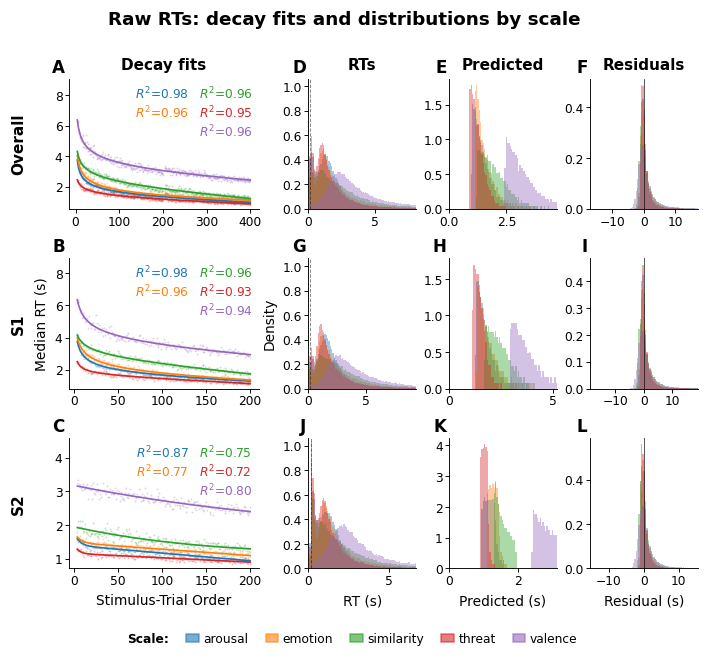

saved -> /home/sjsuss626/EMST_files/sjs_dissertation/dervatives/dynamic_qc/figures/pub_figures/main_text/fig_decay_curves.png (+ fig_decay_curves.json)


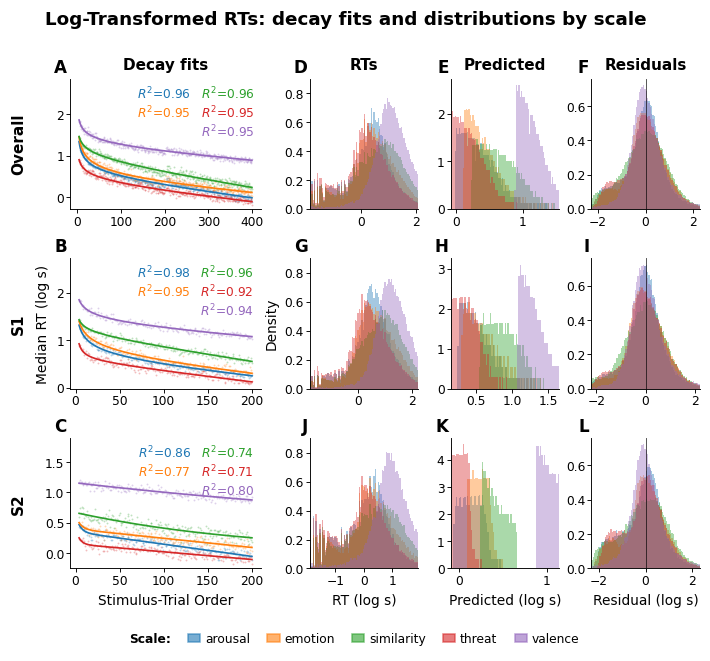

saved -> /home/sjsuss626/EMST_files/sjs_dissertation/dervatives/dynamic_qc/figures/pub_figures/supplement/fig_decay_curves_boxcox.png (+ fig_decay_curves_boxcox.json)


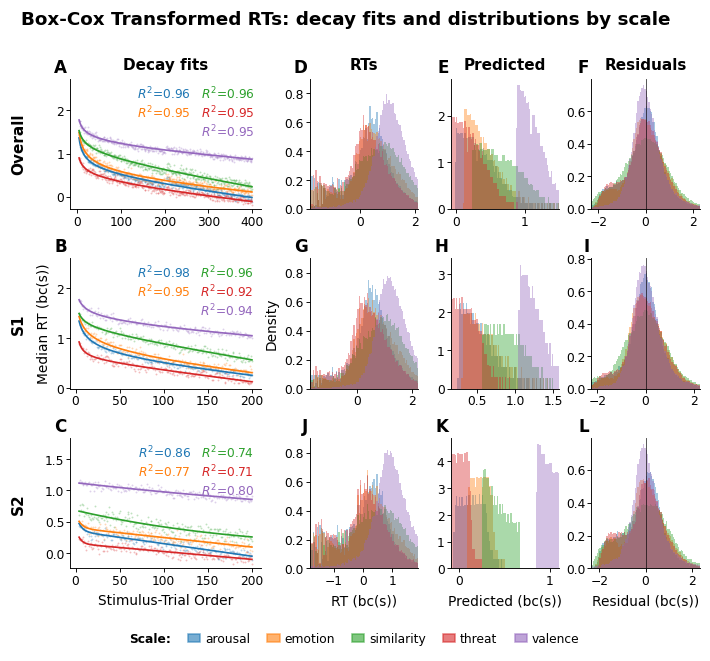

In [2]:
# [cell 2]
# =============================================================================
# DECAY CURVES AND DISTRIBUTIONS: ONE MOSAIC PER TRANSFORM (log: the main-text figure; raw and Box-Cox: supplement)
# =============================================================================
# Left column A/B/C: the decay fits (concatenated sessions, session 1, session 2) -- the median RT per trial position and
# the fitted curve of every scale, from the LVL0 notebook's decay-fit exports. Right block D..L: 3 x 3 densities, ROW =
# the span of the decay panel beside it, COL = RT | predicted | residual (the handoff's columns: *_overall, the
# concatenated fit, in the Overall row; *_per_ses, the per-session fits LVL_1 analyses, in the S1 and S2 rows).
TRANSFORMS = {
    "raw":    dict(rt="rt_sec", pred="predicted_rt_raw_overall", resid=f"drift_residual_raw_overall{_res_sfx}",
                   pred_ses="predicted_rt_raw_per_ses", resid_ses=f"drift_residual_raw_per_ses{_res_sfx}",
                   title="Raw RTs", unit="seconds", name="fig_decay_curves_raw", subdir="supplement"),
    "log":    dict(rt="log_rt", pred="predicted_rt_log_overall", resid=f"drift_residual_log_overall{_res_sfx}",
                   pred_ses="predicted_rt_log_per_ses", resid_ses=f"drift_residual_log_per_ses{_res_sfx}",
                   title="Log-Transformed RTs", unit="log s", name="fig_decay_curves", subdir="main_text"),
    "boxcox": dict(rt="bc_rt", pred="predicted_rt_bc_overall", resid=f"drift_residual_bc_overall{_res_sfx}",
                   pred_ses="predicted_rt_bc_per_ses", resid_ses=f"drift_residual_bc_per_ses{_res_sfx}",
                   title="Box-Cox Transformed RTs", unit="bc(s)", name="fig_decay_curves_boxcox", subdir="supplement"),
}
DECAY_FITS = pd.read_csv(f"{LV0}_decay_fits.csv")
DECAY_CURVES = pd.read_csv(f"{LV0}_decay_curves.csv")
FIG_SIZE = (6.5, 5.9)
PALETTE = ['#1f77b4', '#ff7f0e', '#2ca02c', '#d62728', '#9467bd', '#009E73', '#CC79A7']
SCALE_COLORS = {s: PALETTE[i % len(PALETTE)] for i, s in enumerate(SCALES)}


def build_mosaic(tag):
    spec = TRANSFORMS[tag]
    rt_col, pred_col, res_col = spec["rt"], spec["pred"], spec["resid"]
    spans = [("Overall", None)] + [(f"S{s}", s) for s in SESSIONS]
    fig = plt.figure(figsize=FIG_SIZE)
    outer = fig.add_gridspec(1, 2, width_ratios=[1.0, 2.05], wspace=0.17,
                             left=0.115, right=0.995, top=0.89, bottom=0.135)
    unit = "s" if spec["unit"] == "seconds" else spec["unit"]
    gsL = outer[0, 0].subgridspec(len(spans), 1, hspace=0.38)
    gsR = outer[0, 1].subgridspec(len(spans), 3, hspace=0.38, wspace=0.30)
    last, mid = len(spans) - 1, len(spans) // 2
    rt_axes, decay_axes = [], []
    letters_left = ["A", "B", "C"]
    letters_right = iter(["D", "E", "F", "G", "H", "I", "J", "K", "L"])
    for row, (span_label, ses) in enumerate(spans):
        sub = clean if ses is None else clean[clean["session"] == ses]
        pred_col = spec["pred"] if ses is None else spec["pred_ses"]
        res_col = spec["resid"] if ses is None else spec["resid_ses"]
        # ---- left: decay fit (medians per trial position and the fitted curve, per scale) ----
        ax = fig.add_subplot(gsL[row])
        fits = DECAY_FITS[(DECAY_FITS["table"] == "figure fit") & (DECAY_FITS["transform"] == tag)
                          & (DECAY_FITS["span"] == span_label)].set_index("scale")
        cur = DECAY_CURVES[(DECAY_CURVES["transform"] == tag) & (DECAY_CURVES["span"] == span_label)]
        for scale in SCALES:
            if scale not in fits.index:
                continue
            c = SCALE_COLORS[scale]
            med = cur[(cur["scale"] == scale) & (cur["kind"] == "median")]
            fit = cur[(cur["scale"] == scale) & (cur["kind"] == "fit")]
            ax.scatter(med["x"], med["y"], s=1.5, alpha=0.3, color=c, linewidth=0)
            ax.plot(fit["x"], fit["y"], color=c, lw=1.1, label=f"$R^2$={fits.loc[scale, 'r_squared']:.2f}")
        if row == 0:
            ax.set_title("Decay fits", fontweight="bold", loc="center", fontsize=FS["title"], pad=6)
        if row == mid:
            ax.set_ylabel(f"Median RT ({unit})", fontsize=FS["label"])
        if row == last:
            ax.set_xlabel("Stimulus-Trial Order", fontsize=FS["label"])
        decay_axes.append((ax, span_label))
        ax.tick_params(labelsize=FS["tick"])
        lo, hi = ax.get_ylim()
        ax.set_ylim(lo, hi + 0.4 * (hi - lo))
        _l = [l_ for l_ in ax.get_legend_handles_labels()[1]]
        _h = [plt.Line2D([], [], ls="none", marker="none", color=SCALE_COLORS[s_]) for s_ in SCALES if s_ in fits.index]
        if len(_h) == 5:
            _blank = plt.Line2D([], [], ls="none", marker="none", color="white")
            _h = _h[:2] + [_blank] + _h[2:]
            _l = _l[:2] + [""] + _l[2:]
        ax.legend(_h, _l, fontsize=FS["ann"], loc="upper right", ncol=2, columnspacing=0.8,
                  handlelength=0, handletextpad=0, labelspacing=0.2, borderaxespad=0.1,
                  labelcolor="linecolor")
        panel_letter(ax, letters_left[row])
        # ---- right: RT | predicted | residual densities ----
        xmax_rt = float(sub[rt_col].quantile(0.95))
        xmin_rt = float(sub[rt_col].quantile(0.005)) if tag != "raw" else 0.0
        xmax_pr = float(sub[pred_col].quantile(0.99))
        xmin_pr = float(sub[pred_col].quantile(0.01)) if tag != "raw" else 0.0
        xlim_rs = float(np.abs(sub[res_col].dropna().quantile([0.01, 0.99])).max())
        panels = [(rt_col, f"RT ({unit})", (xmin_rt, xmax_rt), None),
                  (pred_col, f"Predicted ({unit})", (xmin_pr, xmax_pr), None),
                  (res_col, f"Residual ({unit})", (-xlim_rs, xlim_rs), 0.0)]
        for col, (dcol, xlabel, xlim, vline) in enumerate(panels):
            ax = fig.add_subplot(gsR[row, col])
            if col == 0:
                rt_axes.append(ax)
            for scale in SCALES:
                vals = sub.loc[sub["scale"] == scale, dcol].replace([np.inf, -np.inf], np.nan).dropna()
                ax.hist(vals, bins=80, range=xlim, density=True, alpha=0.4, color=SCALE_COLORS[scale], label=scale)
            if vline is not None:
                ax.axvline(vline, color="black", lw=0.6, alpha=0.7)
            if col == 0 and tag == "raw":
                ax.axvline(MIN_RT_THRESH, color="black", ls="--", lw=0.6, alpha=0.5)
            ax.set_xlim(*xlim)
            if row == last:
                ax.set_xlabel(xlabel, fontsize=FS["label"])
            if row == mid and col == 0:
                ax.set_ylabel("Density", fontsize=FS["label"])
            if row == 0:
                ax.set_title(["RTs", "Predicted", "Residuals"][col], fontweight="bold", loc="center",
                             fontsize=FS["title"], pad=6)
            ax.tick_params(labelsize=FS["tick"])
            panel_letter(ax, next(letters_right))
    # RT density column: one y range for D / G / J, ticks every 0.2
    _top = max(0.9, 1.02 * max((p.get_height() for a in rt_axes for p in a.patches), default=0))
    for a in rt_axes:
        a.set_ylim(0, _top)
        a.set_yticks(np.arange(0, _top + 1e-9, 0.2))
    # row titles (Overall / S1 / S2), just left of the decay panels' y label and tick labels
    fig.canvas.draw()
    _r = fig.canvas.get_renderer()
    _inv = fig.transFigure.inverted()
    _left = min(_inv.transform(t.get_window_extent(_r))[0, 0]
                for a, _ in decay_axes
                for t in a.get_yticklabels() + ([a.yaxis.label] if a.get_ylabel() else []) if t.get_text())
    for a, name in decay_axes:
        _y = np.mean(a.get_position().intervaly)
        fig.text(_left - 0.012, _y, name, rotation=90, fontsize=FS["row"], fontweight="bold",
                 va="center", ha="right")
    fig_title(fig, f"{spec['title']}: decay fits and distributions by scale")
    bottom_key(fig, [plt.Rectangle((0, 0), 1, 1, color=SCALE_COLORS[s_], alpha=0.6) for s_ in SCALES],
               list(SCALES), "Scale:")
    return fig


for _tag, _spec in TRANSFORMS.items():
    with plt.rc_context(RC_FIG):
        _fig = build_mosaic(_tag)
        save_figure(_fig, _spec["name"], _spec["subdir"],
                    [f"{LV0}.csv", f"{LV0}_parameters.json", f"{LV0}_decay_fits.csv", f"{LV0}_decay_curves.csv"])
        plt.show()

saved -> /home/sjsuss626/EMST_files/sjs_dissertation/dervatives/dynamic_qc/figures/pub_figures/main_text/fig_lvl1_calibration.png (+ fig_lvl1_calibration.json)


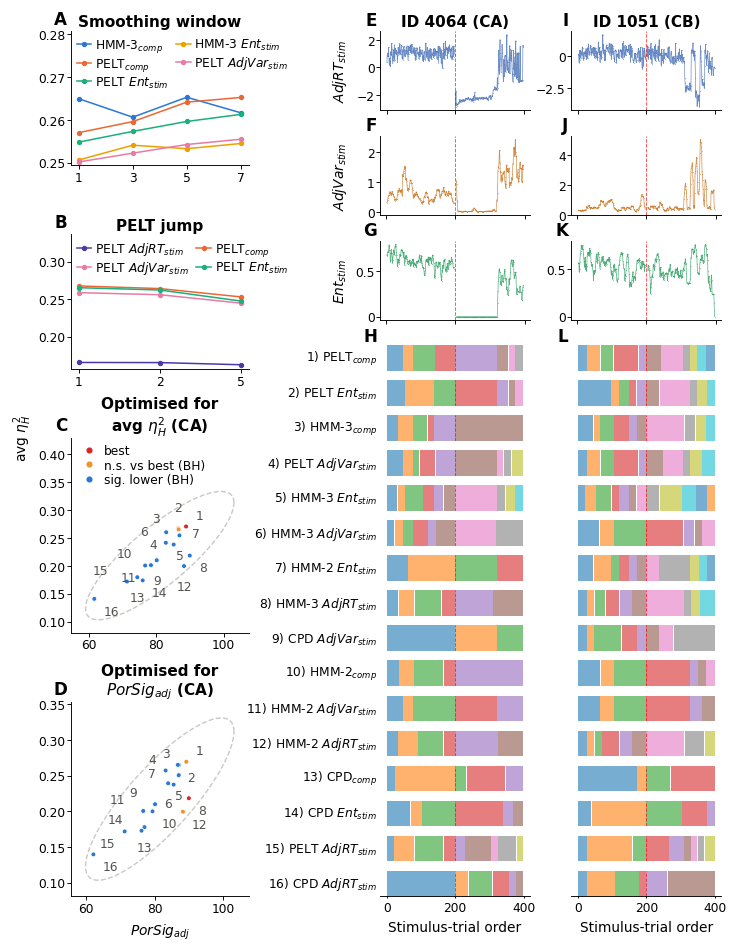

In [3]:
# [cell 3]
# =============================================================================
# LVL1 CALIBRATION (T2 SWEEP) AND TWO SEGMENTED SESSIONS (the main-text calibration figure)
# =============================================================================
# One figure at page width (6.5 in), three columns:
#   col 1  A smoothing_window | B pelt_jump (main effect on the mean effect size, the LVL1 sweep report's configurations)
#          C effect size vs corrected significance (each detector at its η²_H-optimal configuration)
#          D the same at each detector's Corr%-optimal configuration (points numbered by C's rank)
#          colours: red = best, orange = not separable from it (BH), blue = significantly lower, from the groups of
#          the LVL1 notebook's H1 pairwise tests in T2 calibration: C the η²_H test, D the Corr% test (Corr%-optimal);
#          grey dashed ellipse = the single-outlier boundary: Mahalanobis D² from the detectors' centroid (sample
#          covariance) equal to the critical D² of Wilks' (1963) test at α = .05, Bonferroni over the n detectors
#          (p = .05 / n, which is the BH threshold of the smallest p only), as the report's Table 2.8 critical D²
#   col 2  E-G the three detection features and H every detector's blocks, participant MOSAIC_PARTICIPANTS[0]
#   col 3  I-K and L, the same for participant MOSAIC_PARTICIPANTS[1]
# Columns 2-3 plot the LVL_1 detection features of the handoff with the participant-unique block labels the
# detectors produced; only observed values are drawn and the line connects consecutive observed values.
SERIES = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#4a3aa7"]
SEQ, INK, MUTED = "#2a78d6", "#0b0b0b", "#52514e"
EFF, CORR = "avg_effsize", "avg_corr_sig%"
EFF_LABEL_FIG = "avg " + (r"$\eta^2_H$" if str(_l1cfg["validate_test"]).strip("'\"").lower() == "kruskal" else "ω²") 
CFGS = pd.read_csv(LVL_OUTS / f"{LVL1_SWEEP}_report_configs.csv")
chk = pd.read_csv(LVL_OUTS / f"{LVL1_SWEEP}_report_best_eta.csv").set_index("method")
chk_sig = pd.read_csv(LVL_OUTS / f"{LVL1_SWEEP}_report_best_corr.csv").set_index("method")
VARY = [c for c in ("cfg_smoothing_window", "cfg_pelt_jump") if c in CFGS.columns and CFGS[c].nunique() > 1]
_rk = pd.read_csv(f"{HANDOFF}_h1_ranks.csv")
_rk = _rk[(_rk.Dataset == "T2 calibration") & (_rk.Group != "lower")]
H1_GROUP = _rk.loc[_rk.Criterion == "η²_H", "Detector"].tolist()        # best first, then those not separable from it
E_GROUP = _rk.loc[_rk.Criterion == "Corr%", "Detector"].tolist()
WINNER, E_WINNER = chk.index[0], E_GROUP[0]
if not WINNER == SEL1["detector"] == H1_GROUP[0]:
    raise SystemExit(f"the best detector of the sweep's η²_H table ({WINNER}), the selection ({SEL1['detector']}) and the "
                     f"best of the H1 η²_H test ({H1_GROUP[0]}) differ")
FEATURE_TEX = {"Adj_RT_Level_Stim": "$AdjRT_{stim}$", "Adj_RT_Var_win": "$AdjVar_{stim}$",
               "Entropy_win": "$Ent_{stim}$"}
KNOB_TITLE = {"cfg_pelt_jump": "PELT jump", "cfg_smoothing_window": "Smoothing window"}
CORR_LABEL = r"$PorSig_{adj}$"


def method_label(m):
    """PELT_Adj_RT_Var_win -> 'PELT $AdjVar_{stim}$'; HMM_Attention_comp_3 -> 'HMM-3$_{comp}$'."""
    fam, rest = m.split("_", 1)
    states = ""
    if fam == "HMM":
        _m = re.match(r"(\d+)_(.*)", rest) or re.match(r"(.*)_(\d+)$", rest)
        if _m and _m.group(1).isdigit():
            states, rest = _m.group(1), _m.group(2)
        elif _m:
            rest, states = _m.group(1), _m.group(2)
    name = f"{fam}{'-' + states if states else ''}"
    return f"{name}$_{{comp}}$" if rest == "Attention_comp" else f"{name} {FEATURE_TEX.get(rest, rest)}"


def _bbox_overlap(a, b):
    dx = min(a.x1, b.x1) - max(a.x0, b.x0)
    dy = min(a.y1, b.y1) - max(a.y0, b.y0)
    return dx * dy if dx > 0 and dy > 0 else 0.0


def place_labels(ax, xs, ys, labels, fontsize=7, color="#666666", inside=False, obstacles=()):
    """Annotate without overlaps: try candidate offsets, keep the first that collides with no marker, no label already
    placed and no artist in `obstacles`; falls back to the least-overlapping candidate. inside=True also counts any part
    of a label outside the axes as overlap."""
    import matplotlib.transforms as mtransforms
    fig = ax.figure
    fig.canvas.draw()
    rend = fig.canvas.get_renderer()
    cands = [(6, 3, "left", "bottom"), (6, -4, "left", "top"),
             (-6, 3, "right", "bottom"), (-6, -4, "right", "top"),
             (0, 9, "center", "bottom"), (0, -9, "center", "top"),
             (12, 3, "left", "bottom"), (-12, 3, "right", "bottom")]
    taken = [o.get_window_extent(rend) for o in obstacles]
    _ax_bb = ax.get_window_extent(rend)
    for x, y in zip(xs, ys):
        px, py = ax.transData.transform((x, y))
        taken.append(mtransforms.Bbox.from_bounds(px - 5, py - 5, 10, 10))
    for i in np.argsort(ys)[::-1]:
        best = None
        for dx, dy, ha, va in cands:
            t = ax.annotate(labels[i], (xs[i], ys[i]), textcoords="offset points",
                            xytext=(dx, dy), fontsize=fontsize, color=color,
                            ha=ha, va=va, annotation_clip=False)
            bb = t.get_window_extent(rend).expanded(1.06, 1.25).padded(2)
            ov = sum(_bbox_overlap(bb, o) for o in taken)
            if inside:
                ov += bb.width * bb.height - _bbox_overlap(bb, _ax_bb)
            if best is None or ov < best[1]:
                if best is not None:
                    best[0].remove()
                best = (t, ov, bb)
            else:
                t.remove()
            if ov == 0:
                break
        taken.append(best[2])


RANKED = list(chk.index)                                  # best -> worst
_bcols = [f"block_{m}_unique" for m in RANKED]
_resid = str(_l1cfg.get("use_residuals", "True")) == "True"
TRACES = [("aggregated_residual" if _resid else "aggregated_rt", FEATURE_TEX["Adj_RT_Level_Stim"], "#4a72b8"),
          ("local_residual_var" if _resid else "local_rt_var", FEATURE_TEX["Adj_RT_Var_win"], "#c8741f"),
          ("rating_entropy_norm", FEATURE_TEX["Entropy_win"], "#2f9e63")]
_need1 = ["id", "session", "stim_order", "condition"] + [t[0] for t in TRACES] + _bcols
_avail = pd.read_csv(f"{HANDOFF}_features.csv", nrows=0).columns
feat = pd.read_csv(f"{HANDOFF}_features.csv", usecols=[c for c in _need1 if c in _avail])
feat = feat[feat["id"].isin(MOSAIC_PARTICIPANTS)].copy()
_meths = CFGS.groupby("method")[EFF].mean().sort_values(ascending=False).head(5).index.tolist()
_pelt = sorted(m for m in CFGS["method"].unique() if m.startswith("PELT"))
_order = list(dict.fromkeys(list(_meths) + _pelt))
_COLOR = {m: SERIES[i % len(SERIES)] for i, m in enumerate(_order)}
_PANEL = {"cfg_pelt_jump": _pelt}


class _ZeroFormatter(mticker.ScalarFormatter):
    """Default tick labels, with the zero tick written as a plain "0"."""
    def __call__(self, x, pos=None):
        return "0" if abs(x) < 1e-12 else super().__call__(x, pos)


with plt.rc_context(RC_FIG):
    nstrip = len(RANKED)
    _left_axes = []
    plt.rcParams["axes.grid"] = False
    plt.rcParams["ytick.major.pad"] = 0.75 * plt.rcParams["ytick.major.pad"]
    fig = plt.figure(figsize=(6.5, 8.6))
    _outer = fig.add_gridspec(1, 5, width_ratios=[0.95, 0.70, 0.80, 0.22, 0.80], wspace=0,
                              left=0.085, right=0.995, top=0.965, bottom=0.05)
    gsL = _outer[0, 0].subgridspec(4, 1, height_ratios=[1.0, 1.0, 1.45, 1.45], hspace=0.42)
    _colM = _outer[0, 2].subgridspec(2, 1, height_ratios=[3 * 2.4 + 1.2, nstrip], hspace=0.06)
    _colR = _outer[0, 4].subgridspec(2, 1, height_ratios=[3 * 2.4 + 1.2, nstrip], hspace=0.06)
    _tM, _sM = _colM[0].subgridspec(len(TRACES), 1, hspace=0.32), _colM[1].subgridspec(nstrip, 1, hspace=0.35)
    _tR, _sR = _colR[0].subgridspec(len(TRACES), 1, hspace=0.32), _colR[1].subgridspec(nstrip, 1, hspace=0.35)
    gsM = [_tM[k] for k in range(len(TRACES))] + [_sM[k] for k in range(nstrip)]
    gsR = [_tR[k] for k in range(len(TRACES))] + [_sR[k] for k in range(nstrip)]
    # ---- A, B: main effects (A = smoothing, B = PELT jump)
    _AB = sorted(VARY[:2], key=lambda k: k != "cfg_smoothing_window")
    for pos, (k, ch) in enumerate(zip(_AB, ["A", "B"])):
        ax = fig.add_subplot(gsL[pos])
        _left_axes.append(ax)
        for m in _PANEL.get(k, _meths):
            s = CFGS[CFGS.method == m].groupby(k)[EFF].mean().sort_index()
            if s.empty:
                continue
            _x = [f"{v:g}" if isinstance(v, (int, float, np.floating)) else str(v) for v in s.index]
            ax.plot(_x, s.values, marker="o", ms=2.5, lw=1.0, color=_COLOR[m], label=method_label(m))
        ax.set_title(KNOB_TITLE.get(k, k.replace("cfg_", "")), fontweight="bold", loc="center", fontsize=FS["title"], pad=3)
        ax.tick_params(labelsize=FS["tick"])
        lo, hi = ax.get_ylim()
        ax.set_ylim(lo, hi + 0.55 * (hi - lo))
        ax.legend(fontsize=FS["leg"], ncol=2, loc="upper left", frameon=False, handlelength=1.2,
                  handletextpad=0.3, columnspacing=0.6, labelspacing=0.15, borderaxespad=0.1)
        clear_of_data(ax, ax.get_legend())
        panel_letter(ax, ch)
    # ---- C, D: scatters
    for pos, (tbl, sub, ch) in enumerate([(chk, f"Optimised for\n{EFF_LABEL_FIG} (CA)", "C"),
                                          (chk_sig, f"Optimised for\n{CORR_LABEL} (CA)", "D")]):
        ax = fig.add_subplot(gsL[2 + pos])
        _left_axes.append(ax)
        _win, _grp = (WINNER, H1_GROUP) if pos == 0 else (E_WINNER, E_GROUP)
        _clr = ["#d62728" if m == _win else "#f0932b" if m in _grp else SEQ for m in tbl.index]
        ax.scatter(tbl[CORR], tbl[EFF], s=10, color=_clr, zorder=3, edgecolor="white", linewidth=0.5)
        _X = tbl[[CORR, EFF]].to_numpy(float); _n = len(_X)
        # the single-outlier (Bonferroni) boundary: Wilks' critical D² at p = .05 / n
        _crit = (_n - 1) ** 2 / _n * stats.beta.isf(0.05 / _n, 1.0, (_n - 3) / 2.0)
        _th = np.linspace(0, 2 * np.pi, 361)
        _E = _X.mean(axis=0) + np.sqrt(_crit) * np.column_stack([np.cos(_th), np.sin(_th)]) @ np.linalg.cholesky(np.cov(_X.T)).T
        ax.plot(_E[:, 0], _E[:, 1], color="#c9c8c3", lw=0.9, ls="--", zorder=1)
        ax.margins(x=0.10, y=0.10)
        if pos == 0:
            ax.legend(handles=[Line2D([], [], ls="", marker="o", ms=3, color="#d62728", label="best"),
                               Line2D([], [], ls="", marker="o", ms=3, color="#f0932b", label="n.s. vs best (BH)"),
                               Line2D([], [], ls="", marker="o", ms=3, color=SEQ, label="sig. lower (BH)")],
                      fontsize=FS["leg"], loc="upper left", frameon=False, handletextpad=0.2,
                      labelspacing=0.15, borderaxespad=0.1)
            clear_of_data(ax, ax.get_legend())
        place_labels(ax, tbl[CORR].values, tbl[EFF].values, [str(RANKED.index(m) + 1) for m in tbl.index],
                     fontsize=FS["ann"], color=MUTED, inside=True,
                     obstacles=[ax.get_legend()] if ax.get_legend() else [])
        ax.set_title(sub, fontweight="bold", loc="center", fontsize=FS["title"], pad=3)
        ax.tick_params(labelsize=FS["tick"])
        if pos == 1:
            ax.set_xlabel(f"{CORR_LABEL}", fontsize=FS["label"])
        panel_letter(ax, ch)
    # ---- E-L: participants
    strip_colors = plt.cm.tab10(np.linspace(0, 1, 10))
    _trace_axes = []
    for gs, pid, letters, first in [(gsM, MOSAIC_PARTICIPANTS[0], "EFGH", True),
                                    (gsR, MOSAIC_PARTICIPANTS[1], "IJKL", False)]:
        p = feat[feat["id"] == pid].sort_values(["session", "stim_order"]).reset_index(drop=True)
        p["trial_idx"] = np.arange(len(p))
        sess = p["session"].values
        bounds = [p.loc[p["session"] == s, "trial_idx"].min() for s in sorted(p["session"].unique())[1:]]
        for row, (col, ylab, clr) in enumerate(TRACES):
            ax = fig.add_subplot(gs[row])
            x, yv = p["trial_idx"].to_numpy(), p[col].to_numpy(dtype=float)
            for _sv in pd.unique(sess):
                _m = (sess == _sv) & np.isfinite(yv)
                ax.plot(x[_m], yv[_m], "-", color=clr, lw=0.45, alpha=0.8)
                ax.scatter(x[_m], yv[_m], s=0.6, color=clr, alpha=0.5, linewidths=0)
            for b in bounds:
                ax.axvline(b, color="red", ls="--", lw=0.6, alpha=0.7)
            if first:
                ax.set_ylabel(ylab, fontsize=FS["label"])
                _trace_axes.append(ax)
            ax.tick_params(labelsize=FS["tick"], labelbottom=False)
            ax.yaxis.set_major_formatter(_ZeroFormatter())
            if row == 0:
                ax.set_title(f"ID {pid} ({COHORT[p['condition'].iloc[0]]})", fontweight="bold", loc="center",
                             fontsize=FS["title"], pad=3)
            panel_letter(ax, letters[row])
        for j, m in enumerate(RANKED):
            ax = fig.add_subplot(gs[len(TRACES) + j])
            bc = f"block_{m}_unique"
            if bc in p.columns:
                bl = p[bc].values
                for b in np.unique(bl[~pd.isna(bl)]):
                    ax.fill_between(p["trial_idx"], 0, 1, where=(bl == b), alpha=0.6,
                                    color=strip_colors[int(b) % 10], linewidth=0)
            if first:
                ax.set_ylabel(f"{j + 1}) {method_label(m)}", fontsize=FS["strip"], rotation=0,
                              ha="right", va="center", labelpad=2)
            ax.set_ylim(0, 1); ax.set_yticks([])
            for _sp in ("left", "top", "right"):
                ax.spines[_sp].set_visible(False)
            if j == 0:
                panel_letter(ax, letters[len(TRACES)])
            for b in bounds:
                ax.axvline(b, color="red", ls="--", lw=0.6, alpha=0.7)
            last = (j == len(RANKED) - 1)
            ax.tick_params(labelsize=FS["tick"], labelbottom=last, length=1.5 if last else 0)
            if last:
                ax.set_xlabel("Stimulus-trial order", fontsize=FS["label"])
            else:
                ax.spines["bottom"].set_visible(False)
    fig.align_ylabels(_trace_axes)
    fig.canvas.draw()
    _inv = fig.transFigure.inverted()
    _x0 = min(_inv.transform(ax.yaxis.get_tightbbox(fig.canvas.get_renderer()))[0, 0] for ax in _left_axes)
    _ymid = _left_axes[2].get_position().y1
    fig.text(_x0 - 0.006, _ymid, EFF_LABEL_FIG, rotation=90, ha="right", va="center", fontsize=FS["label"])
    save_figure(fig, "fig_lvl1_calibration", "main_text",
                [LVL_OUTS / f"{LVL1_SWEEP}_report_{k}.csv" for k in ("configs", "best_eta", "best_corr")]
                + [f"{HANDOFF}_h1_ranks.csv", f"{HANDOFF}_features.csv", f"{HANDOFF}_meta.json",
                   LVL_OUTS / f"{LVL1_SWEEP}_selection.json"],
                tight=False)
    plt.show()

saved -> /home/sjsuss626/EMST_files/sjs_dissertation/dervatives/dynamic_qc/figures/pub_figures/supplement/fig_feature_distributions.png (+ fig_feature_distributions.json)


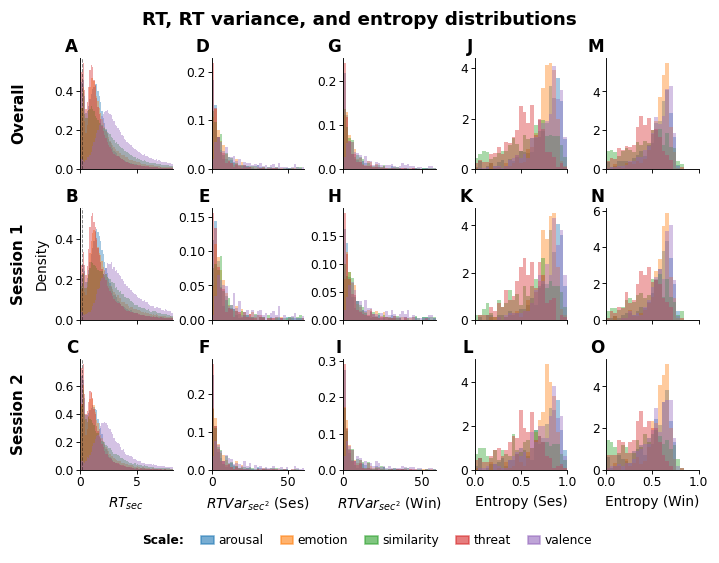

In [4]:
# [cell 4]
# =============================================================================
# RT, RT VARIANCE AND RESPONSE ENTROPY BY SCALE: SESSION-LEVEL AND SLIDING-WINDOW (supplement)
# =============================================================================
# Rows: both sessions (overall), session 1, session 2. Columns: every trial's raw RT (the LVL_0 handoff after the
# intake gates); then, per participant-session x scale, the LVL1 notebook's session features: RT variance over the
# whole session and the session mean of the sliding-window variance (s^2), and normalised response entropy over the
# whole session and the session mean of LVL_1's rolling entropy.
SESS = pd.read_csv(f"{HANDOFF}_report_session_features.csv")
SESS_FEATS = {k: g for k, g in SESS.groupby("feature", sort=False)}
_XLAB = {"Session-level RT variance": "$RTVar_{sec^2}$ (Ses)", "Sliding-window RT variance": "$RTVar_{sec^2}$ (Win)",
         "Session-level entropy": "Entropy (Ses)", "Sliding-window entropy": "Entropy (Win)"}
_COLS = [("RT", "$RT_{sec}$")] + [(k, _XLAB[k]) for k in _XLAB]
_SCOL = {s: PALETTE[i % len(PALETTE)] for i, s in enumerate(SCALES)}
_ROWS = [("Overall", None)] + [(f"Session {s:g}", s) for s in SESSIONS]
with plt.rc_context({**RC_FIG, "axes.grid": False, "ytick.major.pad": 1.5, "xtick.major.pad": 1.5}):
    fig = plt.figure(figsize=(6.5, 5.0))
    gs = fig.add_gridspec(len(_ROWS), len(_COLS), left=0.11, right=0.975, top=0.91, bottom=0.16, hspace=0.35, wspace=0.42)
    _letters = iter("ABCDEFGHIJKLMNO")
    _axes = np.empty((len(_ROWS), len(_COLS)), dtype=object)
    for j, (col_name, xlab) in enumerate(_COLS):
        if j == 0:
            _xlim, _bins = (0.0, float(clean["rt_sec"].quantile(0.95))), 70
        else:
            _t = SESS_FEATS[col_name]
            _xlim = ((0.0, float(_t["value"].quantile(0.95))) if "variance" in col_name else (0.0, 1.0))
            _bins = 35 if "variance" in col_name else 25
        for i, (row_name, ses) in enumerate(_ROWS):
            ax = fig.add_subplot(gs[i, j]); _axes[i, j] = ax
            for s in SCALES:
                if j == 0:
                    d = clean if ses is None else clean[clean["session"] == ses]
                    v = d.loc[d["scale"] == s, "rt_sec"]
                else:
                    d = _t if ses is None else _t[_t["session"] == ses]
                    v = d.loc[d["scale"] == s, "value"]
                ax.hist(v.dropna(), bins=_bins, range=_xlim, density=True, alpha=0.4, color=_SCOL[s])
            if j == 0:
                ax.axvline(MIN_RT_THRESH, color="black", ls="--", lw=0.6, alpha=0.5)
            ax.set_xlim(*_xlim)
            ax.tick_params(labelsize=FS["tick"], labelbottom=(i == len(_ROWS) - 1), length=2.5, width=0.6)
            for sp in ("top", "right"):
                ax.spines[sp].set_visible(False)
            if i == len(_ROWS) - 1:
                ax.set_xlabel(xlab, fontsize=FS["label"])
            if j == 0 and i == len(_ROWS) // 2:
                ax.set_ylabel("Density", fontsize=FS["label"])
            panel_letter(ax, next(_letters))
    fig.canvas.draw()
    _rend = fig.canvas.get_renderer()
    _inv = fig.transFigure.inverted()
    _left = min(_inv.transform(t.get_window_extent(_rend))[0, 0]
                for a in _axes[:, 0] for t in a.get_yticklabels() + [a.yaxis.label] if t.get_text())
    for i, (row_name, _) in enumerate(_ROWS):
        fig.text(_left - 0.012, np.mean(_axes[i, 0].get_position().intervaly), row_name, rotation=90,
                 fontsize=FS["row"], fontweight="bold", va="center", ha="right")
    bottom_key(fig, [plt.Rectangle((0, 0), 1, 1, color=_SCOL[s], alpha=0.6) for s in SCALES], list(SCALES),
               "Scale:")
    fig_title(fig, "RT, RT variance, and entropy distributions")
    save_figure(fig, "fig_feature_distributions", "supplement",
                [f"{LV0}.csv", f"{LV0}_parameters.json", f"{HANDOFF}_report_session_features.csv"], tight=False)
    plt.show()

saved -> /home/sjsuss626/EMST_files/sjs_dissertation/dervatives/dynamic_qc/figures/pub_figures/supplement/fig_age_by_feature.png (+ fig_age_by_feature.json)


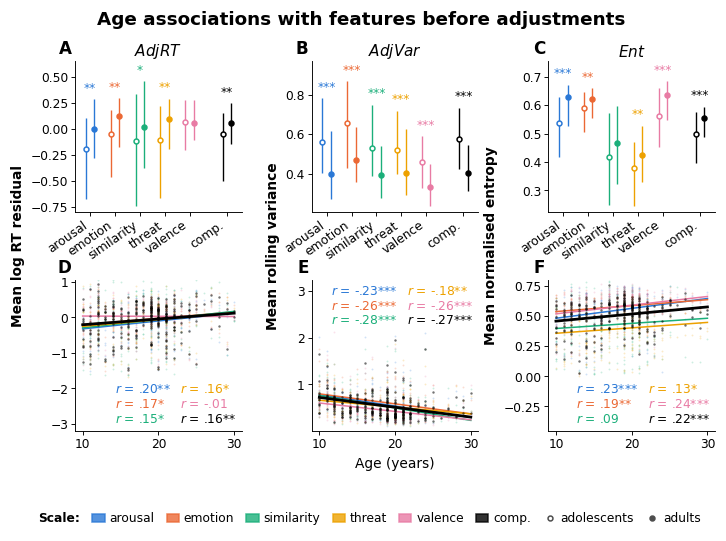

In [5]:
# [cell 5]
# =============================================================================
# AGE ASSOCIATIONS OF THE STIMULUS-LEVEL FEATURES BEFORE THE AGE ADJUSTMENT (supplement)
# =============================================================================
# Top: adolescent (< 18) vs adult median and IQR per scale (open = adolescents, filled = adults), with the BH-FDR
# significance of the Mann-Whitney test (composite: uncorrected). Bottom: participant means against age with each
# scale's OLS line (composite in black) and Pearson r. From the LVL1 notebook's age-check exports.
AGE_P = pd.read_csv(f"{HANDOFF}_report_age_participants.csv")
AGE_CONT = pd.read_csv(f"{HANDOFF}_report_age_continuous.csv")
AGE_GRP = pd.read_csv(f"{HANDOFF}_report_age_groups.csv")
FAMILIES = ["AdjRT", "AdjVar", "Ent"]
ROWS = list(SCALES) + ["comp."]
_tag = {"raw": "raw", "log": "log", "boxcox": "bc"}[str(_l1cfg["feature_rt_transform"]).strip("'\"")]
_SC = {s: SERIES[i % len(SERIES)] for i, s in enumerate(SCALES)} | {"comp.": "black"}
_FAM_TEX = {"AdjRT": "$AdjRT$", "AdjVar": "$AdjVar$", "Ent": "$Ent$"}
_FAM_UNIT = {"AdjRT": f"Mean {_tag} RT residual", "AdjVar": "Mean rolling variance", "Ent": "Mean normalised entropy"}
_R_LOC = {"AdjRT": "lower right", "AdjVar": "upper right", "Ent": "lower right"}
_stars = lambda p: "***" if p < .001 else "**" if p < .01 else "*" if p < .05 else ""
_f2 = lambda v: f"{v:.2f}".replace("0.", ".", 1) if abs(v) < 1 else f"{v:.2f}"
with plt.rc_context({**RC_FIG, "axes.grid": False, "ytick.major.pad": 2.0, "xtick.major.pad": 2.0}):
    fig, axes = plt.subplots(2, 3, figsize=(6.5, 4.8))
    fig.subplots_adjust(left=0.10, right=0.995, top=0.90, bottom=0.20, wspace=0.42, hspace=0.45)
    _ages = np.linspace(AGE_P.age.min(), AGE_P.age.max(), 50)
    for j, fam in enumerate(FAMILIES):
        ax = axes[1, j]
        _v = AGE_P[[f"{fam}::{s}" for s in ROWS]].stack()
        _lo, _hi = _v.quantile([.01, .99]); _pad = 0.08 * (_hi - _lo)
        for s in ROWS:
            d = AGE_P[["age", f"{fam}::{s}"]].dropna()
            d = d[d[f"{fam}::{s}"].between(_lo - _pad, _hi + _pad)]
            c = AGE_CONT[(AGE_CONT.family == fam) & (AGE_CONT.scale == s)].iloc[0]
            comp = s == "comp."
            ax.scatter(d["age"], d[f"{fam}::{s}"], s=2.5 if comp else 1.5, color=_SC[s],
                       alpha=0.55 if comp else 0.22, linewidths=0, zorder=3 if comp else 2)
            ax.plot(_ages, c.intercept + c.slope * _ages, color=_SC[s], lw=1.8 if comp else 1.0, zorder=4 if comp else 3)
        _rh, _rl = [], []
        for s in ROWS:
            c = AGE_CONT[(AGE_CONT.family == fam) & (AGE_CONT.scale == s)].iloc[0]
            _rh.append(Line2D([], [], ls="none", marker="none", color=_SC[s]))
            _rl.append(f"$r$ = {_f2(c.r)}{_stars(c.p if s == 'comp.' else c.p_FDR)}")
        _rkey = ax.legend(_rh, _rl, loc=_R_LOC[fam], ncol=2, fontsize=FS["tick"], labelcolor="linecolor",
                  handlelength=0, handletextpad=0, columnspacing=0.8, labelspacing=0.15,
                  borderaxespad=0.15, frameon=True, facecolor="white", edgecolor="none",
                  framealpha=0.85, borderpad=0.25)
        ax.set_ylim(_lo - _pad, _hi + _pad)
        ax.tick_params(labelsize=FS["tick"])
        panel_letter(ax, "DEF"[j])
        clear_of_data(ax, _rkey)
        ax = axes[0, j]
        ax.set_title(_FAM_TEX[fam], fontsize=FS["title"], fontweight="bold", pad=3)
        _xpos = list(range(len(SCALES))) + [len(SCALES) + 0.5]
        for k, s in zip(_xpos, ROWS):
            g = AGE_GRP[(AGE_GRP.family == fam) & (AGE_GRP.scale == s)].iloc[0]
            for dx, grp, face in ((-0.17, "adolescent", "white"), (0.17, "adult", _SC[s])):
                v = AGE_P.loc[AGE_P.group == grp, f"{fam}::{s}"].dropna()
                q1, med, q3 = v.quantile([.25, .5, .75])
                ax.errorbar(k + dx, med, yerr=[[med - q1], [q3 - med]], fmt="o", ms=3.2,
                            mfc=face, mec=_SC[s], ecolor=_SC[s], elinewidth=0.9, capsize=0, zorder=3)
            _top = max(AGE_P.loc[AGE_P.group == grp_, f"{fam}::{s}"].quantile(.75) for grp_ in ("adolescent", "adult"))
            _pp = g.p if s == "comp." else g.p_FDR
            if not _stars(_pp):
                continue
            ax.annotate(_stars(_pp), (k, _top), textcoords="offset points", xytext=(0, 3), ha="center", va="bottom",
                        fontsize=FS["ann"], color=_SC[s])
        ax.set_xticks(_xpos, ROWS, rotation=35, ha="right", fontsize=FS["tick"])
        ax.set_xlim(-0.6, _xpos[-1] + 0.6)
        lo, hi = ax.get_ylim(); ax.set_ylim(lo, hi + 0.10 * (hi - lo))
        ax.tick_params(axis="y", labelsize=FS["tick"])
        panel_letter(ax, "ABC"[j])
    fig.canvas.draw()
    for j, fam in enumerate(FAMILIES):
        _t, _b = axes[0, j].get_position(), axes[1, j].get_position()
        _r = fig.canvas.get_renderer()
        _x = min(t.get_window_extent(_r).x0 for a in (axes[0, j], axes[1, j]) for t in a.get_yticklabels() if t.get_text())
        _x = fig.transFigure.inverted().transform((_x, 0))[0]
        fig.text(_x - 0.008, (_t.y1 + _b.y0) / 2, _FAM_UNIT[fam], rotation=90, ha="right", va="center", fontsize=FS["label"],
                 fontweight="bold")
    bottom_xlabel(fig, axes[1, :], "Age (years)")
    bottom_key(fig, [plt.Rectangle((0, 0), 1, 1, color=_SC[s], alpha=0.8) for s in ROWS]
               + [Line2D([], [], ls="", marker="o", ms=3.2, mfc="white", mec="0.3"),
                  Line2D([], [], ls="", marker="o", ms=3.2, mfc="0.3", mec="0.3")],
               ROWS + ["adolescents", "adults"], "Scale:", columnspacing=1.0)
    fig_title(fig, "Age associations with features before adjustments")
    save_figure(fig, "fig_age_by_feature", "supplement",
                [f"{HANDOFF}_report_age_participants.csv", f"{HANDOFF}_report_age_continuous.csv",
                 f"{HANDOFF}_report_age_groups.csv", f"{HANDOFF}_meta.json", f"{LV0}.csv", f"{LV0}_parameters.json"],
                tight=False)
    plt.show()

saved -> /home/sjsuss626/EMST_files/sjs_dissertation/dervatives/dynamic_qc/figures/pub_figures/supplement/fig_dose_response.png (+ fig_dose_response.json)


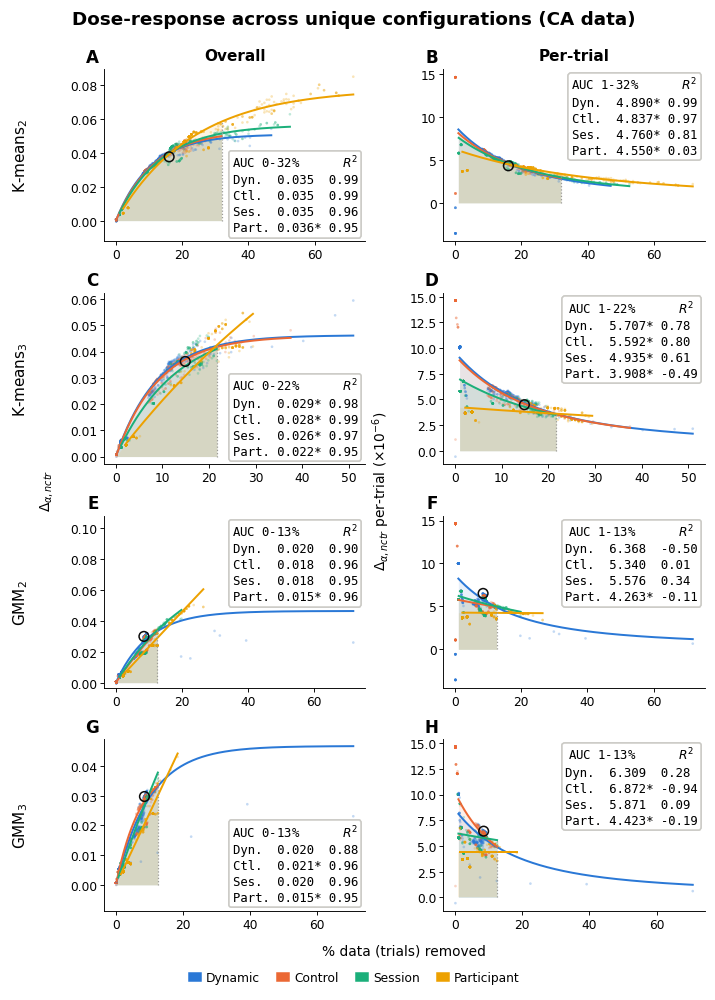

In [6]:
# [cell 6]
# =============================================================================
# DOSE-RESPONSE OF THE ALPHA GAIN ACROSS THE LVL2 SWEEP (supplement): arms stacked, overall | per trial
# =============================================================================
# Points = sweep configurations (the LVL2 sweep report's dose points); lines = the report's saturating fits
# a(1 - e^(-b v)) over each design's observed doses; shading = the area integrated for the AUC (dotted line = its upper
# bound); open circle = the calibrated configuration; * = AUC differs from every other design in that panel: q < .05
# in each of the design's contrasts in the LVL2 sweep report's primary dose contrasts (the paired bootstrap over the
# arm's distinct solutions, BH within the overall and per-trial families). The cell stops when those contrasts' AUCs
# are not the fitted AUCs or when the dose fits' stars differ from these.
PTS = pd.read_csv(LVL_OUTS / f"{LVL2_SWEEP}_report_dose_points.csv")
FITS = pd.read_csv(LVL_OUTS / f"{LVL2_SWEEP}_report_dose_fits.csv")
PICKD = pd.read_csv(LVL_OUTS / f"{LVL2_SWEEP}_report_dose_picks.csv").set_index("Arm")
CONTR = pd.read_csv(LVL_OUTS / f"{LVL2_SWEEP}_report_dose_contrasts.csv")
if not {"n_solutions", "n_configs"} <= set(CONTR.columns):
    raise SystemExit(f"{LVL2_SWEEP}_report_dose_contrasts.csv is not the distinct-solution test (no n_solutions, "
                     "n_configs): rerun LVL2_sweep_report")
_pair = CONTR.Comparison.str.split(" − ")
_auc = FITS.set_index(["Arm", "Family", "Design"])["AUC"]
_at = lambda j: _auc.reindex(pd.MultiIndex.from_arrays([CONTR.Arm, CONTR.Family, _pair.str[j]])).to_numpy(float)
_off = CONTR.loc[~(np.isclose(CONTR["AUC A"], _at(0), rtol=1e-6, equal_nan=True)
                   & np.isclose(CONTR["AUC B"], _at(1), rtol=1e-6, equal_nan=True)), ["Arm", "Family", "Comparison"]]
if len(_off):
    raise SystemExit(f"the primary dose contrasts' AUCs are not the dose fits' AUCs:\n{_off.to_string(index=False)}")


def _differs(arm, kind, d):
    """The design's AUC differs from every other design of the panel: q < .05 in each of its primary contrasts."""
    g = CONTR[(CONTR.Arm == arm) & (CONTR.Family == kind) & _pair.map(lambda p: d in p)]
    others = set(FITS[(FITS.Arm == arm) & (FITS.Family == kind)].Design) - {d}
    return len(g) > 0 and {x for p in _pair[g.index] for x in p} - {d} == others and bool((g.q < .05).all())


STARS = {(r.Arm, r.Family, r.Design): _differs(r.Arm, r.Family, r.Design) for r in FITS.itertuples()}
_fstar = FITS.set_index(["Arm", "Family", "Design"]).get("Differs from every other design (q < .05)")
_off = [] if _fstar is None else [k for k, v in STARS.items() if v != (str(_fstar[k]) == "True")]
if _off:
    raise SystemExit(f"{LVL2_SWEEP}_report_dose_fits.csv: stars that differ from its primary dose contrasts' at {_off}")
DESIGNS = ["dynamic", "control", "session", "participant"]
DCOL = dict(zip(DESIGNS, SERIES))
FIG_LAB = {"dynamic": "Dynamic", "control": "Control", "session": "Session", "participant": "Participant"}
BOX_LAB = {"dynamic": "Dyn.", "control": "Ctl.", "session": "Ses.", "participant": "Part."}
KINDS = {"overall": r"$\Delta_{\alpha,nctr}$", "per-trial": r"$\Delta_{\alpha,nctr}$ per-trial (×10$^{-6}$)"}
KIND_LAB = {"overall": "Overall", "per-trial": "Per-trial"}
AUC_BOX_LOC = {("mixture_gmm_2", "overall"): "upper right"}
_ok = PTS[(PTS.Pct_Removed > 0) & (PTS.Trials_Removed > 0)]
N_TRIALS = float((100 * _ok.Trials_Removed / _ok.Pct_Removed).mean())
PT = 100.0 / N_TRIALS / 1e-6          # gain / % removed x PT = gain per trial removed, in 1e-6 units
PER_FROM = float(FITS.loc[FITS.Family == "per-trial", "AUC range (%)"].iloc[0].split("–")[0])
_sat = lambda v, a, b: a * (1.0 - np.exp(-b * v))
ARMS_D = list(dict.fromkeys(FITS.Arm))
with plt.rc_context(RC_FIG):
    _YROW = (len(ARMS_D) - 1) // 2
    fig, axes = plt.subplots(len(ARMS_D), len(KINDS), figsize=(6.5, 2.25 * len(ARMS_D)), squeeze=False)
    fig.subplots_adjust(left=0.15, right=0.99, top=0.935, bottom=0.085, wspace=0.30, hspace=0.30)
    for r, m in enumerate(ARMS_D):
        sub = PTS[PTS.Removal_Method == m]
        for c, (kind, ylab) in enumerate(KINDS.items()):
            ax = axes[r, c]
            f_ = FITS[(FITS.Arm == m) & (FITS.Family == kind)].set_index("Design")
            hi = float(f_["AUC range high (%)"].iloc[0])
            tops = []
            for d in DESIGNS:
                if d not in f_.index:
                    continue
                s = sub[sub.Design == d]
                y = PT * s.Alpha_Excess / s.Pct_Removed if kind == "per-trial" else s.Alpha_Excess
                ax.scatter(s.Pct_Removed, y, s=3, alpha=0.28, color=DCOL[d], edgecolor="none")
                a, b = f_.loc[d, "a (ceiling)"], f_.loc[d, "b (rate)"]
                xs = np.linspace(max(PER_FROM if kind == "per-trial" else 0.2, s.Pct_Removed.min()), s.Pct_Removed.max(), 200)
                ax.plot(xs, PT * _sat(xs, a, b) / xs if kind == "per-trial" else _sat(xs, a, b), color=DCOL[d], lw=1.3,
                        label=FIG_LAB[d])
                xa = np.linspace(PER_FROM if kind == "per-trial" else 1e-6, hi, 200)
                ya = PT * _sat(xa, a, b) / xa if kind == "per-trial" else _sat(xa, a, b)
                ax.fill_between(xa, 0, ya, color=DCOL[d], alpha=0.10, linewidth=0, zorder=0)
                tops.append(ya[-1])
            if tops and np.isfinite(np.nanmax(tops)):
                ax.vlines(hi, 0, np.nanmax(tops), color="#9b9a95", lw=0.8, ls=":")
            if m in PICKD.index:
                pk = PICKD.loc[m]
                yk = pk["Per trial (× 10⁻⁶)"] if kind == "per-trial" else pk["Alpha excess"]
                ax.scatter([pk["% trials removed"]], [yk], s=40, facecolor="none", edgecolor=INK, linewidth=1.0, zorder=6)
            _lo = PER_FROM if kind == "per-trial" else 0.0
            rows = [f"{BOX_LAB[d]:<6}{f_.loc[d, 'AUC']:.3f}{('*' if STARS[(m, kind, d)] else ''):<2}"
                    f"{f_.loc[d, 'R²']:.2f}" for d in DESIGNS if d in f_.index]
            _leg = ax.legend([Line2D([], [], alpha=0)] * len(rows), rows, loc=AUC_BOX_LOC.get((m, kind), "best"),
                             handlelength=0, handletextpad=0, title=f"{'AUC ' + f'{_lo:.0f}-{hi:.0f}%':<13}  $R^2$",
                             prop=dict(family="monospace", size=FS["box"]),
                             title_fontproperties=dict(family="monospace", size=FS["box"]),
                             frameon=True, framealpha=0.9, edgecolor="#c9c8c3", borderpad=0.25,
                             labelspacing=0.25, borderaxespad=0.3)
            ax.add_artist(_leg)
            clear_of_data(ax, _leg)
            ax.grid(False)
            ax.set_ylabel(ylab if r == _YROW else "", fontsize=FS["label"])
            ax.set_xlabel("% data (trials) removed" if (r, c) == (len(ARMS_D) - 1, 0) else "", fontsize=FS["label"])
            ax.tick_params(labelsize=FS["tick"], length=2.5, pad=2)
            if r == 0:
                ax.set_title(KIND_LAB[kind])
            panel_letter(ax, chr(65 + len(KINDS) * r + c))
    bottom_key(fig, [plt.Rectangle((0, 0), 1, 1, color=DCOL[d]) for d in DESIGNS], [FIG_LAB[d] for d in DESIGNS])
    fig.canvas.draw()
    _rend, _inv = fig.canvas.get_renderer(), fig.transFigure.inverted()
    for c_ in range(len(KINDS)):
        _ax = axes[_YROW, c_]; _pos = _ax.get_position()
        _bb = _ax.yaxis.label.get_window_extent(_rend)
        _x = _ax.transAxes.inverted().transform((0.5 * (_bb.x0 + _bb.x1), 0))[0]
        _iv = [axes[r_, c_].get_position().intervaly for r_ in range(len(ARMS_D))]
        _mid = 0.5 * (min(v[0] for v in _iv) + max(v[1] for v in _iv))
        _ax.yaxis.set_label_coords(_x, (_mid - _pos.y0) / _pos.height)
    _axb = axes[-1, 0]; _posb = _axb.get_position()
    _bbx = _axb.xaxis.label.get_window_extent(_rend)
    _yb = _axb.transAxes.inverted().transform((0, 0.5 * (_bbx.y0 + _bbx.y1)))[1]
    _ivx = [axes[-1, c_].get_position().intervalx for c_ in range(len(KINDS))]
    _midx = 0.5 * (min(v[0] for v in _ivx) + max(v[1] for v in _ivx))
    _axb.xaxis.set_label_coords((_midx - _posb.x0) / _posb.width, _yb)
    left_headers(fig, axes[:, 0], [SOL_TEX(m) for m in ARMS_D])
    fig_title(fig, "Dose-response across unique configurations (CA data)")
    save_figure(fig, "fig_dose_response", "supplement",
                [LVL_OUTS / f"{LVL2_SWEEP}_report_{k}.csv" for k in ("dose_points", "dose_fits", "dose_picks",
                                                                     "dose_contrasts")], tight=False)
    plt.show()

saved -> /home/sjsuss626/EMST_files/sjs_dissertation/dervatives/dynamic_qc/figures/pub_figures/supplement/fig_gmm_posterior.png (+ fig_gmm_posterior.json)


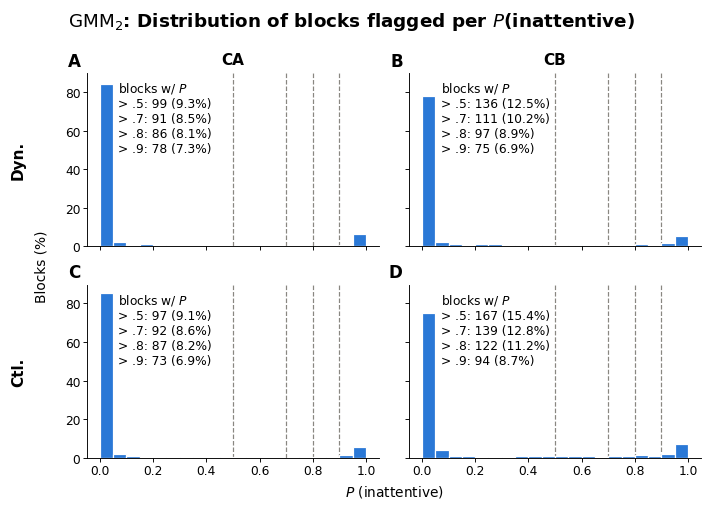

In [7]:
# [cell 7]
# =============================================================================
# GMM: THE POSTERIOR P(INATTENTIVE) PER BLOCK (supplement; the final report's Figure 5.1)
# =============================================================================
# Histograms of P(inattentive) (bins of .05; % of the panel's blocks): rows = dynamic and control blocks, columns = T2
# and T3, from the LVL_2 runs' posterior exports; dashed lines mark the thresholds, and the box gives the blocks above each.
GMM_LAB = next(SOL_TEX(a) for _, a in PICKS.values() if a.startswith("mixture_gmm"))

_P = {}
for run, p in RUN.items():
    z = np.load(f"{p}_post_replicates.npz")
    names = json.loads(str(z["index"]))
    _P.update({n: z[f"r{i}"] for i, n in enumerate(names) if n.startswith("posterior|")})
THRESH = sorted({float(t) for t in json.load(open(f"{RUN['T2']}_parameters.json"))["parameters"]["gmm_posterior_thresholds"]})
_tlab = lambda t: f"> {t:g}".replace("0.", ".")
GMM_COLS = [("T2 calibration", COHORT["T2"]), ("T3 only", COHORT["T3"])]
GMM_ROWS = [("dynamic", "Dyn."), ("control", "Ctl.")]
with plt.rc_context(RC_FIG):
    fig, axes = plt.subplots(len(GMM_ROWS), len(GMM_COLS), figsize=(6.5, 4.6), sharex=True, sharey=True)
    fig.subplots_adjust(left=0.13, right=0.99, top=0.87, bottom=0.11, wspace=0.10, hspace=0.22)
    for i, (des, _) in enumerate(GMM_ROWS):
        for j, (ds, col_name) in enumerate(GMM_COLS):
            ax = axes[i, j]; p = np.asarray(_P[f"posterior|{ds}|{des}"], float); p = p[np.isfinite(p)]
            ax.hist(p, bins=np.linspace(0, 1, 21), weights=np.full(len(p), 100 / len(p)), color="#2a78d6",
                    edgecolor="white", linewidth=0.8)
            for t in THRESH:
                ax.axvline(t, color="#898781", linestyle="--", linewidth=0.8, zorder=0)
            ax.text(0.07, 0.96, "blocks w/ $P$\n" + "\n".join(f"{_tlab(t)}: {int((p > t).sum())} ({100 * (p > t).mean():.1f}%)"
                                                             for t in THRESH),
                    transform=ax.get_xaxis_transform(), ha="left", va="top", fontsize=FS["box"],
                    bbox=dict(facecolor="white", edgecolor="none", pad=1.5))
            if i == 0:
                ax.set_title(col_name)
            panel_letter(ax, chr(65 + len(GMM_COLS) * i + j))
    left_headers(fig, axes[:, 0], [lab for _, lab in GMM_ROWS], ylabel="Blocks (%)")
    bottom_xlabel(fig, axes[-1, :], "$P$ (inattentive)")
    fig_title(fig, f"{GMM_LAB}: Distribution of blocks flagged per $P$(inattentive)")
    save_figure(fig, "fig_gmm_posterior", "supplement",
                [f"{p}_post_replicates.npz" for p in RUN.values()]
                + [f"{RUN['T2']}_parameters.json", LVL_OUTS / f"{LVL2_SWEEP}_selection.json"], tight=False)
    plt.show()


saved -> /home/sjsuss626/EMST_files/sjs_dissertation/dervatives/dynamic_qc/figures/pub_figures/supplement/participants/fig_participant_4064.png (+ fig_participant_4064.json)


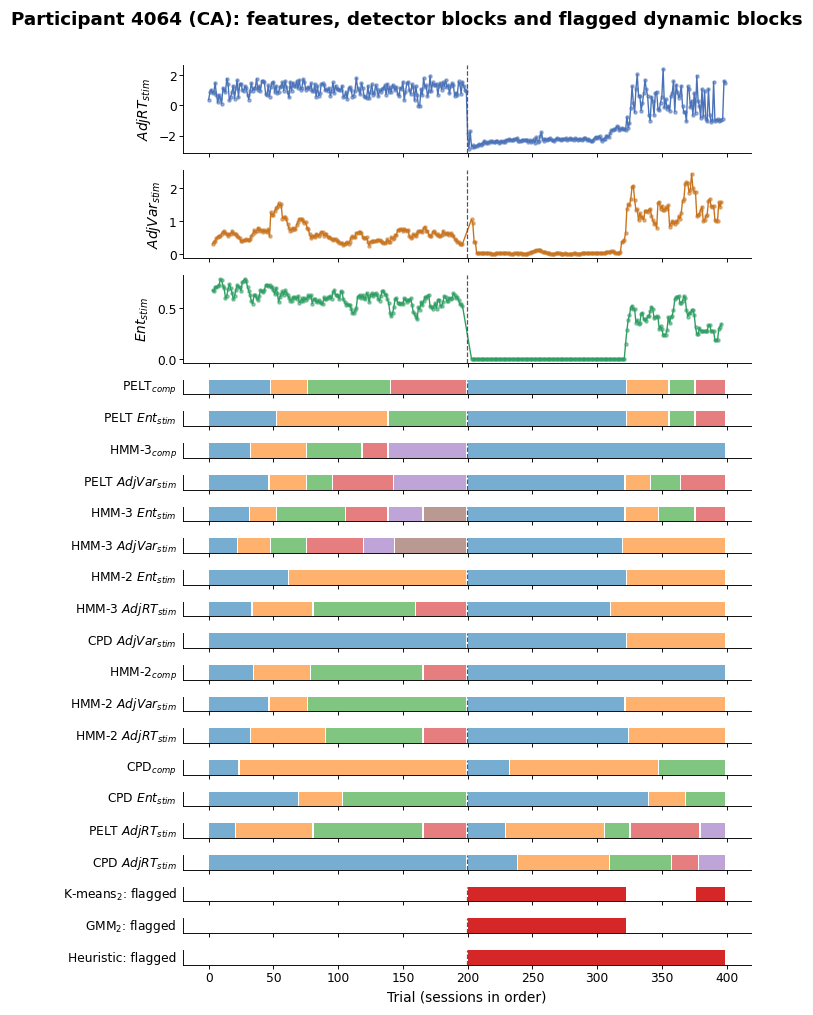

saved -> /home/sjsuss626/EMST_files/sjs_dissertation/dervatives/dynamic_qc/figures/pub_figures/supplement/participants/fig_participant_1051.png (+ fig_participant_1051.json)


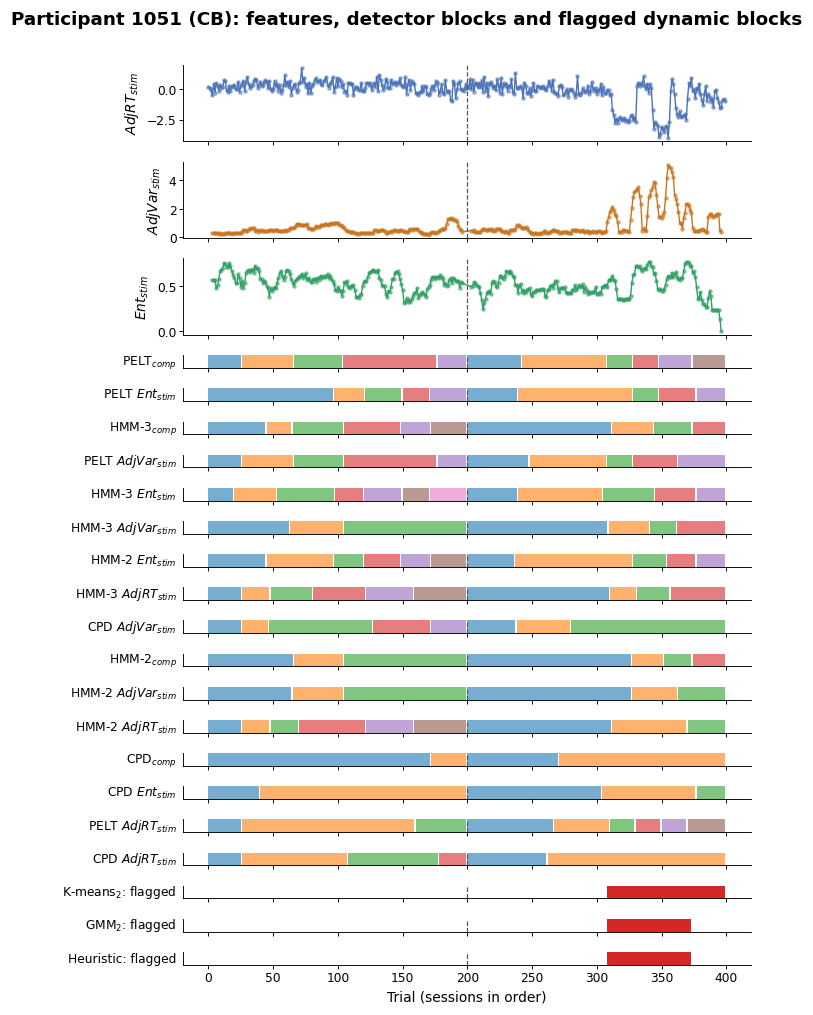

In [8]:
# [cell 9]
# =============================================================================
# PARTICIPANT SESSIONS (supplement/participants): one figure per id in PARTICIPANT_FIGURES
# =============================================================================
# Both sessions in trial order (the dashed line marks the session boundary): the three LVL_1 detection features of the
# handoff (observed values only), every detector's blocks (labels restart in each session; colours repeat every ten),
# and the trials whose dynamic block is flagged by each carried solution and by the behavioural heuristic, from the
# participant's LVL_2 run (T2 or T3).
_FLAG = [(SOL_TEX_LAB[lab], arm) for lab, (_, arm) in PICKS.items()] + [("Heuristic", "inattent_behav")]
_pcols = ["id", "session", "stim_order", "condition"] + [t[0] for t in TRACES] + [f"block_{m}" for m in RANKED]
_pav = pd.read_csv(f"{HANDOFF}_features.csv", nrows=0).columns
_pf = pd.read_csv(f"{HANDOFF}_features.csv", usecols=[c for c in _pcols if c in _pav])
_pf = _pf[_pf["id"].isin(PARTICIPANT_FIGURES)]
_absent = sorted(set(PARTICIPANT_FIGURES) - set(_pf["id"]))
if _absent:
    raise SystemExit(f"PARTICIPANT_FIGURES: not in the analysed sample of {HANDOFF.name}: {_absent}")
_STRIP = plt.cm.tab10(np.linspace(0, 1, 10))
for pid in PARTICIPANT_FIGURES:
    with plt.rc_context(RC_FIG):
        d = _pf[_pf["id"] == pid].sort_values(["session", "stim_order"]).reset_index(drop=True)
        cond = str(d["condition"].iloc[0]); _run = RUN[cond]
        _fc = [f"{arm}_bb_dynamic" for _, arm in _FLAG]
        _a = pd.read_csv(f"{_run}_annotated.csv", usecols=["id", "session", "stim_order"] + _fc)
        _a = _a[_a["id"] == pid].groupby(["session", "stim_order"])[_fc].max().reset_index()
        d = d.merge(_a, on=["session", "stim_order"], how="left")
        x = np.arange(len(d))
        _bnd = [int(d.index[d["session"] == s_][0]) for s_ in sorted(d["session"].unique())[1:]]
        _nb, _nf = len(RANKED), len(_FLAG)
        fig, axes = plt.subplots(len(TRACES) + _nb + _nf, 1, sharex=True,
                                 figsize=(6.5, 1.5 * len(TRACES) + 0.2 * (_nb + _nf) + 0.9),
                                 gridspec_kw={"height_ratios": [6] * len(TRACES) + [1] * (_nb + _nf)})
        for k, (col, lab, clr) in enumerate(TRACES):
            ax = axes[k]; y = d[col].to_numpy(float); ok = np.isfinite(y)
            ax.plot(x[ok], y[ok], "-", color=clr, lw=0.9)
            ax.scatter(x[ok], y[ok], s=4, color=clr, alpha=0.5)
            ax.set_ylabel(lab, fontsize=FS["label"])
            ax.tick_params(labelsize=FS["tick"])
            ax.spines[["top", "right"]].set_visible(False)
        for k, m in enumerate(RANKED):
            ax = axes[len(TRACES) + k]
            b = d[f"block_{m}"].to_numpy(float) if f"block_{m}" in d.columns else np.full(len(d), np.nan)
            for s_ in sorted(d["session"].unique()):
                sm = (d["session"] == s_).to_numpy()
                for blk in np.unique(b[sm & np.isfinite(b)]):
                    ax.fill_between(x, 0, 1, where=sm & (b == blk), color=_STRIP[int(blk) % 10], alpha=0.6, lw=0, step="mid")
            ax.set_yticks([]); ax.set_ylim(0, 1)
            ax.set_ylabel(method_label(m), rotation=0, ha="right", va="center", fontsize=FS["strip"])
        for k, (lab, arm) in enumerate(_FLAG):
            ax = axes[len(TRACES) + _nb + k]
            ax.fill_between(x, 0, 1, where=d[f"{arm}_bb_dynamic"].fillna(0).to_numpy() == 1, color="#d62728", lw=0, step="mid")
            ax.set_yticks([]); ax.set_ylim(0, 1)
            ax.set_ylabel(f"{lab}: flagged", rotation=0, ha="right", va="center", fontsize=FS["strip"])
        for ax in axes:
            for _b0 in _bnd:
                ax.axvline(_b0 - 0.5, color="#555555", ls="--", lw=0.8)
        axes[-1].set_xlabel("Trial (sessions in order)", fontsize=FS["label"])
        axes[-1].tick_params(labelsize=FS["tick"])
        fig_title(fig, f"Participant {pid} ({COHORT[cond]}): features, detector blocks and flagged dynamic blocks")
        fig.tight_layout(rect=(0, 0, 1, 0.985))
        save_figure(fig, f"fig_participant_{pid}", "supplement/participants",
                    [f"{HANDOFF}_features.csv", f"{_run}_annotated.csv", f"{HANDOFF}_meta.json",
                     LVL_OUTS / f"{LVL1_SWEEP}_report_best_eta.csv", LVL_OUTS / f"{LVL2_SWEEP}_selection.json"])
        plt.show()


saved -> /home/sjsuss626/EMST_files/sjs_dissertation/dervatives/dynamic_qc/figures/pub_figures/supplement/fig_method_agreement.png (+ fig_method_agreement.json)


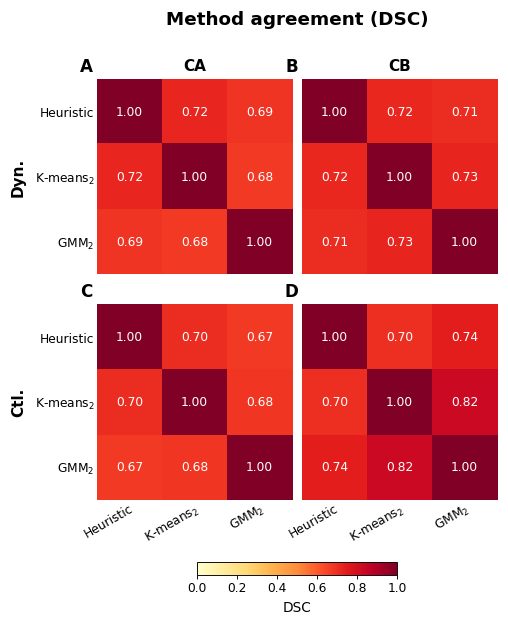

In [9]:
# [cell 10]
# =============================================================================
# METHOD AGREEMENT: DSC BETWEEN THE BEHAVIOURAL HEURISTIC AND THE CARRIED SOLUTIONS (supplement)
# =============================================================================
# Pairwise Dice (DSC) of the units each method flags: rows = dynamic and control blocks, columns = T2 and T3. Units and
# flags come from each run's annotated export (a unit is flagged when its trials are); the heuristic pairs and unit
# counts are checked against the run's DSC export.
AG_ARMS = [("Heuristic", "inattent_behav")] + [(lab, arm) for lab, (_, arm) in PICKS.items()]
AG_UNIT = {"dynamic": f"block_{SEL2['analysis_method']}", "control": f"block_Fixed_{SEL2['analysis_method']}_based"}
AG_ROWS = [("dynamic", "Dyn."), ("control", "Ctl.")]
AG_COLS = [("T2", COHORT["T2"]), ("T3", COHORT["T3"])]


def _dsc(a, b):
    n = a.sum() + b.sum()
    return 2 * (a & b).sum() / n if n else np.nan


AG, _ag_inputs = {}, []
for _rk, _ in AG_COLS:
    _flag_cols = [f"{arm}_bb_{des}" for _, arm in AG_ARMS for des in AG_UNIT]
    _ann = pd.read_csv(f"{RUN[_rk]}_annotated.csv", usecols=["id", "session"] + list(AG_UNIT.values()) + _flag_cols)
    _ref = pd.read_csv(f"{RUN[_rk]}_post_dsc_designs.csv")
    _ag_inputs += [f"{RUN[_rk]}_annotated.csv", f"{RUN[_rk]}_post_dsc_designs.csv"]
    for des, ucol in AG_UNIT.items():
        _f = [f"{arm}_bb_{des}" for _, arm in AG_ARMS]
        _u = _ann.dropna(subset=[ucol]).groupby(["id", "session", ucol])[_f].max().fillna(0) > 0
        M = np.array([[_dsc(_u[a].to_numpy(), _u[b].to_numpy()) for b in _f] for a in _f])
        for i, (lab, _) in enumerate(AG_ARMS[1:], 1):
            r = _ref[(_ref.Solution == lab) & (_ref.Design == des)].iloc[0]
            if len(_u) != r.Units or abs(M[0, i] - r.DSC) > 1e-12:
                raise SystemExit(f"{RUN[_rk].name} {des} {lab}: {len(_u)} units, DSC {M[0, i]:.6f}; "
                                 f"the run's DSC export has {r.Units} units, DSC {r.DSC:.6f}")
        AG[(_rk, des)] = M
_ag_lab = [SOL_TEX_LAB.get(lab, lab) for lab, _ in AG_ARMS]
with plt.rc_context(RC_FIG):
    fig, axes = plt.subplots(len(AG_ROWS), len(AG_COLS), figsize=(6.5, 5.7), sharex=True, sharey=True)
    fig.subplots_adjust(left=0.22, right=0.78, top=0.89, bottom=0.21, wspace=0.05, hspace=0.12)
    for i, (des, _) in enumerate(AG_ROWS):
        for j, (rk, col_name) in enumerate(AG_COLS):
            ax = axes[i, j]; M = AG[(rk, des)]
            im = ax.imshow(M, cmap="YlOrRd", vmin=0, vmax=1)
            for a in range(len(_ag_lab)):
                for b in range(len(_ag_lab)):
                    ax.text(b, a, f"{M[a, b]:.2f}", ha="center", va="center", fontsize=FS["ann"],
                            color="white" if M[a, b] > 0.6 else "black")
            ax.set_xticks(range(len(_ag_lab)), _ag_lab)
            ax.set_yticks(range(len(_ag_lab)), _ag_lab)
            ax.tick_params(length=0)
            ax.spines[["left", "bottom"]].set_visible(False)
            if i == 0:
                ax.set_title(col_name)
            panel_letter(ax, chr(65 + len(AG_COLS) * i + j))
    for ax in axes[-1]:
        plt.setp(ax.get_xticklabels(), rotation=30, ha="right", rotation_mode="anchor")
    left_headers(fig, axes[:, 0], [lab for _, lab in AG_ROWS])
    fig.canvas.draw()                                  # the squares' drawn extent (equal aspect)
    _p0, _p1 = axes[-1, 0].get_position(), axes[-1, -1].get_position()
    _w = 0.5 * (_p1.x1 - _p0.x0)
    _cax = fig.add_axes([0.5 * (_p0.x0 + _p1.x1) - _w / 2, _p0.y0 - 0.12, _w, 0.02])
    _cb = fig.colorbar(im, cax=_cax, orientation="horizontal")
    _cb.set_label("DSC", fontsize=FS["label"]); _cb.ax.tick_params(labelsize=FS["tick"])
    fig_title(fig, "Method agreement (DSC)")
    save_figure(fig, "fig_method_agreement", "supplement", _ag_inputs + [LVL_OUTS / f"{LVL2_SWEEP}_selection.json"],
                tight=False)
    plt.show()


saved -> /home/sjsuss626/EMST_files/sjs_dissertation/dervatives/dynamic_qc/figures/pub_figures/supplement/fig_sweep_overlap.png (+ fig_sweep_overlap.json)


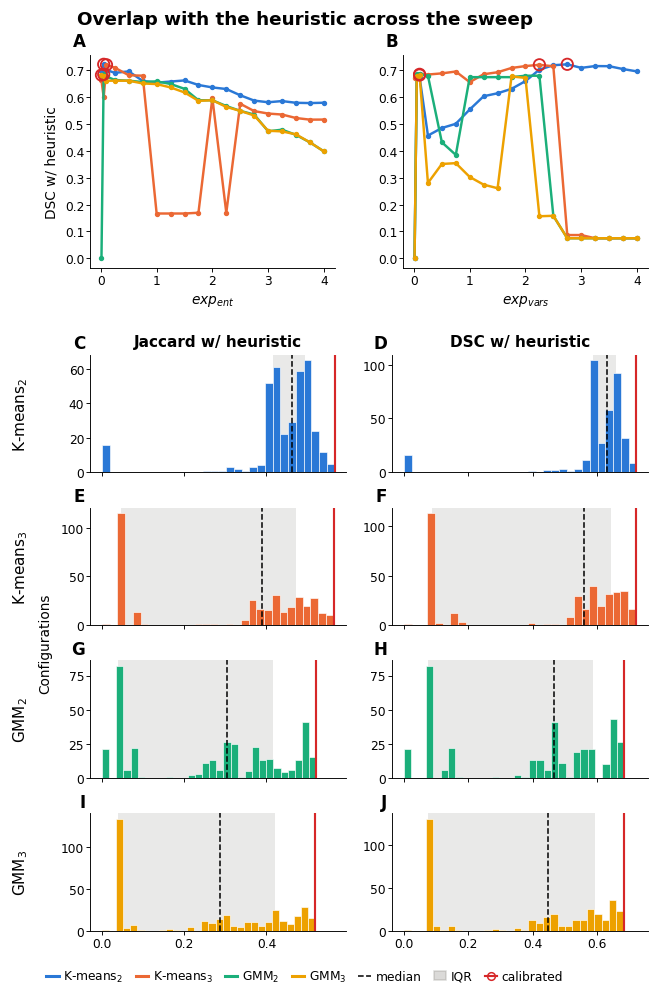

In [10]:
# [cell 11]
# =============================================================================
# OVERLAP WITH THE A-PRIORI STANDARD ACROSS THE LVL2 SWEEP (supplement)
# =============================================================================
# Dynamic blocks of the T2 calibration sweep. A-B: DSC with the behavioural heuristic (the a-priori standard) against
# each exponent, the other exponent held at the arm's calibrated value; circles = the calibrated configurations.
# C-J: the distribution of Jaccard and DSC over all the arm's configurations (median dashed, IQR shaded, calibrated
# configuration red). From the LVL2 sweep report's DSC export; Jaccard = DSC / (2 - DSC).
OV = pd.read_csv(LVL_OUTS / f"{LVL2_SWEEP}_report_dsc_configs.csv")
OV = OV[OV.design == "dynamic"].assign(J=lambda d: d.DSC / (2 - d.DSC))
OV_PICK = pd.read_csv(LVL_OUTS / f"{LVL2_SWEEP}_report_dsc_picks.csv").set_index("Arm")["Config"]
ARMS = list(OV_PICK.index)
ARM_LAB = {a: SOL_TEX(a) for a in ARMS}
ARM_COL = {a: SERIES[i % len(SERIES)] for i, a in enumerate(ARMS)}
OV_EXP = [("exp_entropy", "$exp_{ent}$"), ("exp_rt_var", "$exp_{vars}$")]
PICK_RED = "#d62728"
with plt.rc_context(RC_FIG):
    fig = plt.figure(figsize=(6.5, 9.0))
    _gs = fig.add_gridspec(2, 1, height_ratios=[1.0, 2.7], hspace=0.22, left=0.20, right=0.98, top=0.95, bottom=0.065)
    _top = _gs[0].subgridspec(1, 2, wspace=0.28)
    _bot = _gs[1].subgridspec(len(ARMS), 2, wspace=0.18, hspace=0.30)
    for j, (x, xlab) in enumerate(OV_EXP):
        held = OV_EXP[1 - j][0]
        ax = fig.add_subplot(_top[0, j])
        for a in ARMS:
            t = OV[OV.arm == a]; pk = t[t.config == OV_PICK[a]].iloc[0]
            g = t[t[held] == pk[held]].sort_values(x)
            ax.plot(g[x], g.DSC, color=ARM_COL[a], lw=1.6, marker="o", ms=2.5)
            ax.scatter(pk[x], pk.DSC, s=55, facecolor="none", edgecolor=PICK_RED, linewidth=1.2, zorder=5)
        ax.set_xlabel(xlab)
        if j == 0:
            ax.set_ylabel("DSC w/ heuristic")
        panel_letter(ax, chr(65 + j))
    _hax = np.empty((len(ARMS), 2), dtype=object)
    for i, a in enumerate(ARMS):
        for j, (col, lab) in enumerate((("J", "Jaccard w/ heuristic"), ("DSC", "DSC w/ heuristic"))):
            ax = fig.add_subplot(_bot[i, j], sharex=_hax[0, j] if i else None)
            v = OV.loc[OV.arm == a, col].dropna()
            pv = OV.loc[(OV.arm == a) & (OV.config == OV_PICK[a]), col].iloc[0]
            ax.axvspan(v.quantile(.25), v.quantile(.75), color="#898781", alpha=0.18, lw=0)
            ax.hist(v, bins=30, color=ARM_COL[a], edgecolor="white", linewidth=0.4)
            ax.axvline(v.median(), color="black", lw=1.0, ls="--")
            ax.axvline(pv, color=PICK_RED, lw=1.4)
            if i < len(ARMS) - 1:
                ax.tick_params(labelbottom=False)
            if i == 0:
                ax.set_title(lab)
            panel_letter(ax, chr(67 + 2 * i + j))
            _hax[i, j] = ax
    left_headers(fig, _hax[:, 0], [ARM_LAB[a] for a in ARMS], ylabel="Configurations")
    bottom_key(fig, [Line2D([], [], color=ARM_COL[a], lw=2) for a in ARMS]
               + [Line2D([], [], color="black", ls="--", lw=1.0), plt.Rectangle((0, 0), 1, 1, color="#898781", alpha=0.3),
                  Line2D([], [], color=PICK_RED, lw=1.4, marker="o", mfc="none", ms=5)],
               [ARM_LAB[a] for a in ARMS] + ["median", "IQR", "calibrated"], columnspacing=1.0)
    fig_title(fig, "Overlap with the heuristic across the sweep")
    save_figure(fig, "fig_sweep_overlap", "supplement",
                [LVL_OUTS / f"{LVL2_SWEEP}_report_{k}.csv" for k in ("dsc_configs", "dsc_picks")], tight=False)
    plt.show()


saved -> /home/sjsuss626/EMST_files/sjs_dissertation/dervatives/dynamic_qc/figures/pub_figures/supplement/fig_sweep_profiles.png (+ fig_sweep_profiles.json)


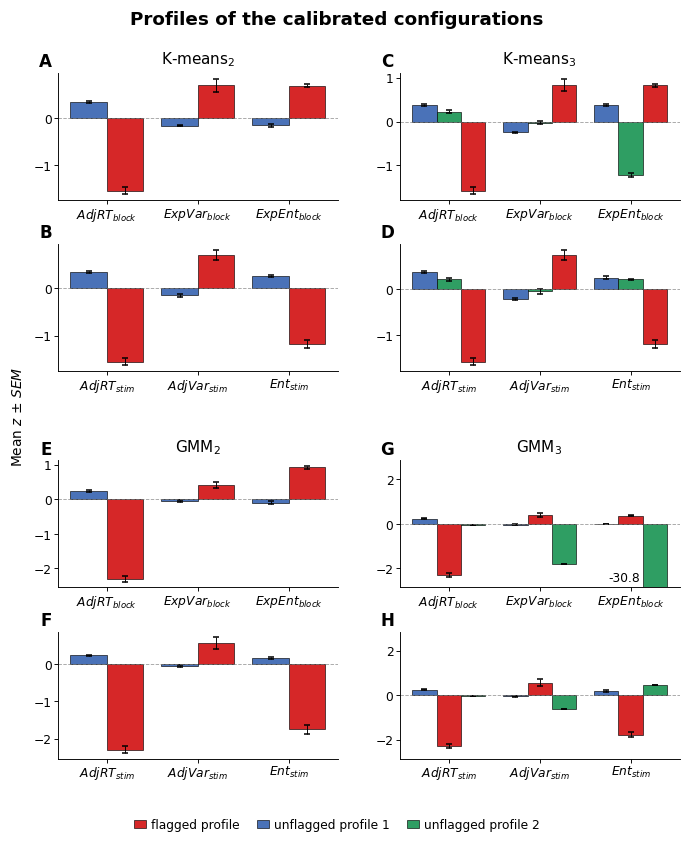

In [11]:
# [cell 12]
# =============================================================================
# PROFILES OF THE CALIBRATED CONFIGURATIONS (supplement)
# =============================================================================
# Each arm of the T2 calibration sweep at its calibrated configuration (dynamic blocks), the arms in a 2 x 2 layout:
# the classification features (upper panel) and the LVL_1 features of the same blocks, unfolded (lower panel). Every
# feature is z-scored across blocks; bars = profile mean z ± SEM, the flagged profile in red. A profile far off the
# scale of the others (fewer than 5 blocks) is clipped and its value written at the clip. From the LVL2 sweep's
# stability-stage profile files and the LVL_1 handoff.
_STAB = SWEEPS_DIR / LVL2_SWEEP / "stability"
_pf_files = {a: _STAB / f"{OV_PICK[a]}__{a}_profiles.csv" for a in ARMS}
_absent = [str(p) for p in _pf_files.values() if not p.exists()]
if _absent:
    raise SystemExit("profile files of the calibrated configurations not found (the LVL2 sweep's --stage stability):\n  "
                     + "\n  ".join(_absent))
_L1F = {c: lab for c, lab, _ in TRACES}
_bcol = f"block_{SEL2['analysis_method']}"
_l1b = pd.read_csv(f"{HANDOFF}_features.csv", usecols=["id", "session", "condition", _bcol] + list(_L1F))
_l1b = (_l1b[_l1b.condition == SEL2["condition"]].groupby(["id", "session", _bcol])[list(_L1F)].mean()
        .reset_index().rename(columns={_bcol: "block"}))
_PF_OTHER = ["#4a72b8", "#2f9e63", "#8c8c8c"]


def _profile_bars(ax, df, cols, labels, flagged_profile):
    z = (df[cols] - df[cols].mean()) / df[cols].std(ddof=1)
    profs = sorted(df.profile.unique())
    width, xs, others = 0.8 / len(profs), np.arange(len(cols)), iter(_PF_OTHER)
    bars = {}
    for i, p in enumerate(profs):
        g = z[df.profile == p]
        mu, sem = g.mean(), g.std(ddof=1) / np.sqrt(len(g))
        bars[p] = (xs + (i - len(profs) / 2 + 0.5) * width, mu, len(g))
        ax.bar(bars[p][0], mu, width, yerr=sem.fillna(0), capsize=2, edgecolor="black", linewidth=0.4,
               error_kw=dict(lw=0.6), color=PICK_RED if p == flagged_profile else next(others))
    big = [b for b in bars.values() if b[2] >= 5]
    if big and len(big) < len(bars):
        lim = 1.25 * max(np.nanmax(np.abs(b[1].to_numpy())) for b in big)
        ax.set_ylim(-lim, lim)
        for x, mu, n in bars.values():
            for xx, v in zip(x, mu):
                if abs(v) > lim:
                    ax.annotate(f"{v:.1f}", (xx - 0.6 * width, np.sign(v) * lim * 0.85), ha="right", va="center",
                                fontsize=FS["ann"])
    ax.axhline(0, color="gray", ls="--", alpha=0.7, lw=0.6)
    ax.set_xticks(xs, [labels[c] for c in cols])


_L2F = {"adj_rt_level_block": "$AdjRT_{block}$", "exp_rt_var_block": "$ExpVar_{block}$",
        "exp_entropy_block": "$ExpEnt_{block}$"}
with plt.rc_context(RC_FIG):
    fig = plt.figure(figsize=(6.5, 7.6))
    _gs = fig.add_gridspec(2, 2, left=0.11, right=0.98, top=0.92, bottom=0.10, wspace=0.22, hspace=0.30)
    _left, _k = [], 0
    for n, a in enumerate(ARMS):
        sub = _gs[n // 2, n % 2].subgridspec(2, 1, hspace=0.35)
        prof = pd.read_csv(_pf_files[a]).merge(_l1b, on=["id", "session", "block"], how="left")
        gmm = "_gmm" if a.startswith("mixture") else ""
        cols2 = ["adj_rt_level_block", f"exp_rt_var_block{gmm}", f"exp_entropy_block{gmm}"]
        fl = prof.loc[prof.flagged, "profile"]
        flagged_profile = fl.mode().iloc[0] if len(fl) else None
        for r, (cols, labels) in enumerate(((cols2, {c: _L2F[c.removesuffix("_gmm")] for c in cols2}), (list(_L1F), _L1F))):
            ax = fig.add_subplot(sub[r])
            _profile_bars(ax, prof, cols, labels, flagged_profile)
            if r == 0:
                ax.set_title(ARM_LAB[a])
            panel_letter(ax, "ABCDEFGH"[2 * n + r])
            if n % 2 == 0:
                _left.append(ax)
    left_headers(fig, _left, ylabel="Mean $z$ ± $SEM$")
    bottom_key(fig, [plt.Rectangle((0, 0), 1, 1, color=c, ec="black", lw=0.4) for c in [PICK_RED] + _PF_OTHER[:2]],
               ["flagged profile", "unflagged profile 1", "unflagged profile 2"])
    fig_title(fig, "Profiles of the calibrated configurations")
    save_figure(fig, "fig_sweep_profiles", "supplement",
                list(_pf_files.values()) + [LVL_OUTS / f"{LVL2_SWEEP}_report_dsc_picks.csv", f"{HANDOFF}_features.csv",
                                            f"{HANDOFF}_meta.json", LVL_OUTS / f"{LVL2_SWEEP}_selection.json"],
                tight=False)
    plt.show()


saved -> /home/sjsuss626/EMST_files/sjs_dissertation/dervatives/dynamic_qc/figures/pub_figures/main_text/fig_h3_designs.png (+ fig_h3_designs.json)


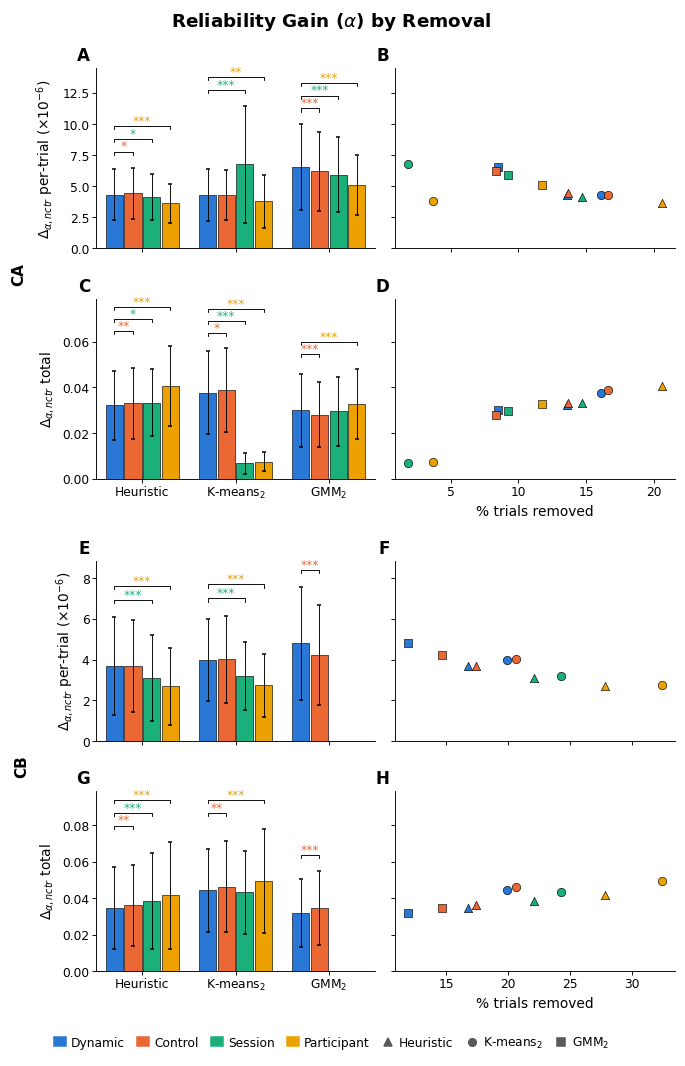

In [12]:
# [cell 13]
# =============================================================================
# H3: DESIGNS COMPARED, T2 AND T3 (main text)
# =============================================================================
# T2 above, T3 below; in each, the alpha gain vs the matched null, per trial removed (upper row) and total (lower row).
# Left: bars = mean ± SD over the scales (the supplement's all-measures figures: ± SEM) (the LVL_2 runs' Step 9 design summary); brackets = dynamic vs each design
# (Step 9 design tests, BH q within panel); an empty slot = a degenerate design. Right: the same means against the %
# of trials each design removes (Step 8). The behavioural heuristic and both carried solutions.
H3_DESIGNS = ["dynamic", "control", "session", "participant"]
H3_DCOL = dict(zip(H3_DESIGNS, SERIES))
H3_DLAB = {"dynamic": "Dynamic", "control": "Control", "session": "Session", "participant": "Participant"}
H3_SOL = {"Heuristic": "inattent_behav"} | {lab: arm for lab, (_, arm) in PICKS.items()}
H3_MARK = dict(zip(H3_SOL, ["^", "o", "s"]))
H3_SHOW = {"Excess per trial": 1e6, "Per trial": 1e6}
H3_RUNS = ["T2", "T3"]
S9 = {rk: (pd.read_csv(f"{RUN[rk]}_step9_design_summary.csv"), pd.read_csv(f"{RUN[rk]}_step9_design_tests.csv"),
           pd.read_csv(f"{RUN[rk]}_step8_multimetric.csv").groupby(["Removal_Method", "Design"]).Pct_Removed.first())
      for rk in H3_RUNS}
_h3_inputs = [f"{RUN[rk]}_{k}.csv" for rk in H3_RUNS for k in ("step9_design_summary", "step9_design_tests",
                                                                 "step8_multimetric")]


def _h3_cell(rk, metric, quantity, sol, design, err="sem"):
    s = S9[rk][0]
    r = s[(s.Metric == metric) & (s.Quantity == quantity) & (s.Condition == rk) & (s.Removal_Method == H3_SOL[sol])
          & (s.Design == design)]
    if not len(r) or not bool(r.Eligible.iloc[0]):
        return np.nan, np.nan
    f = H3_SHOW.get(quantity, 1.0)
    return float(r["mean"].iloc[0]) * f, float(r[err].iloc[0]) * f


def h3_bars(ax, rk, metric, quantity, sols, step_frac=0.09, err="sem"):
    """Bars per solution x design (mean ± err: "sem" or "sd") and the dynamic-vs-design brackets with their significance stars."""
    x, w = np.arange(len(sols)), 0.8 / len(H3_DESIGNS)
    tops = np.full((len(H3_DESIGNS), len(sols)), np.nan)
    for j, d in enumerate(H3_DESIGNS):
        ms = np.array([_h3_cell(rk, metric, quantity, s, d, err) for s in sols])
        ax.bar(x - 0.4 + w * (j + 0.5), ms[:, 0], w * 0.92, yerr=ms[:, 1], capsize=1.5, color=H3_DCOL[d],
               edgecolor="black", linewidth=0.4, error_kw=dict(lw=0.6))
        tops[j] = ms[:, 0] + np.nan_to_num(ms[:, 1])
    ax.axhline(0, color="black", lw=0.6)
    ax.set_xticks(x, [SOL_TEX_LAB.get(s, s) for s in sols])
    ax.set_xlim(-0.5, len(sols) - 0.5)
    t = S9[rk][1]
    if np.isfinite(tops).any():
        step = step_frac * max(np.nanmax(tops) - min(0, np.nanmin(tops)), 1e-12)
        for gi, s in enumerate(sols):
            if not np.isfinite(tops[:, gi]).any():
                continue
            base, lvl, x0 = np.nanmax(tops[:, gi]), 0, x[gi] - 0.4 + w * 0.5
            for j, d in enumerate(H3_DESIGNS[1:], 1):
                r = t[(t.Metric == metric) & (t.Quantity == quantity) & (t.Condition == rk)
                      & (t.Removal_Method == H3_SOL[s]) & (t.Comparison == f"dynamic vs {d}")]
                st = r.stars.iloc[0] if len(r) and isinstance(r.stars.iloc[0], str) else ""
                if not st:
                    continue
                lvl += 1
                y, x2 = base + step * lvl, x[gi] - 0.4 + w * (j + 0.5)
                ax.plot([x0, x0, x2, x2], [y, y + step * 0.25, y + step * 0.25, y], lw=0.6, color="black")
                ax.text((x0 + x2) / 2, y + step * 0.15, st, ha="center", va="bottom", fontsize=FS["ann"],
                        color=H3_DCOL[d])
    ax.margins(y=0.12)


def h3_scatter(ax, rk, metric, quantity, sols):
    """The bar means against the % of trials the design removes (one point per solution x design)."""
    for s in sols:
        for d in H3_DESIGNS:
            m, _ = _h3_cell(rk, metric, quantity, s, d)
            if np.isfinite(m):
                ax.scatter(S9[rk][2][(H3_SOL[s], d)], m, s=30, marker=H3_MARK[s], color=H3_DCOL[d], edgecolor="black",
                           linewidth=0.4, zorder=3)
    ax.axhline(0, color="gray", ls="--", lw=0.6)


H3_MAIN_SOL = list(H3_SOL)
H3_MAIN_ROWS = [
    ("Excess per trial", r"$\Delta_{\alpha,nctr}$ per-trial (×10$^{-6}$)"),
    ("Excess", r"$\Delta_{\alpha,nctr}$ total")
]
with plt.rc_context(RC_FIG):
    fig = plt.figure(figsize=(6.5, 9.6))
    _outer = fig.add_gridspec(len(H3_RUNS), 1, hspace=0.20, left=0.17, right=0.98, top=0.94, bottom=0.085)
    _k = 0
    for b, rk in enumerate(H3_RUNS):
        _g = _outer[b].subgridspec(len(H3_MAIN_ROWS), 2, wspace=0.07, hspace=0.28)
        _blk = []
        for i, (q, ylab) in enumerate(H3_MAIN_ROWS):
            axb = fig.add_subplot(_g[i, 0])
            axs = fig.add_subplot(_g[i, 1], sharey=axb, sharex=_blk[1] if _blk else None)
            h3_bars(axb, rk, "Alpha", q, H3_MAIN_SOL, err="sd")
            h3_scatter(axs, rk, "Alpha", q, H3_MAIN_SOL)
            axb.set_ylabel(ylab)
            axs.tick_params(labelleft=False)
            if i < len(H3_MAIN_ROWS) - 1:
                axb.tick_params(labelbottom=False); axs.tick_params(labelbottom=False)
            else:
                axs.set_xlabel("% trials removed")
            for ax in (axb, axs):
                panel_letter(ax, chr(65 + _k)); _k += 1
            _blk += [axb, axs]
        fig.canvas.draw()                                  # the dataset as a bold row header left of its block
        _x = min(_drawn(fig, [t for a in _blk[::2] for t in a.get_yticklabels() + [a.yaxis.label]], 0))
        _ys = [v for a in _blk[::2] for v in a.get_position().intervaly]
        fig.text(_x - 0.012, 0.5 * (min(_ys) + max(_ys)), COHORT[rk], rotation=90, ha="right", va="center",
                 fontsize=FS["row"], fontweight="bold")
    bottom_key(fig, [plt.Rectangle((0, 0), 1, 1, color=H3_DCOL[d]) for d in H3_DESIGNS]
               + [Line2D([], [], ls="", marker=H3_MARK[s], color="0.35", ms=5) for s in H3_MAIN_SOL],
               [H3_DLAB[d] for d in H3_DESIGNS] + [SOL_TEX_LAB.get(s, s) for s in H3_MAIN_SOL], columnspacing=1.0)
    fig_title(fig, r"Reliability Gain ($\alpha$) by Removal")
    save_figure(fig, "fig_h3_designs", "main_text", _h3_inputs + [LVL_OUTS / f"{LVL2_SWEEP}_selection.json"],
                tight=False)
    plt.show()


saved -> /home/sjsuss626/EMST_files/sjs_dissertation/dervatives/dynamic_qc/figures/pub_figures/supplement/fig_irr_designs_T2.png (+ fig_irr_designs_T2.json)


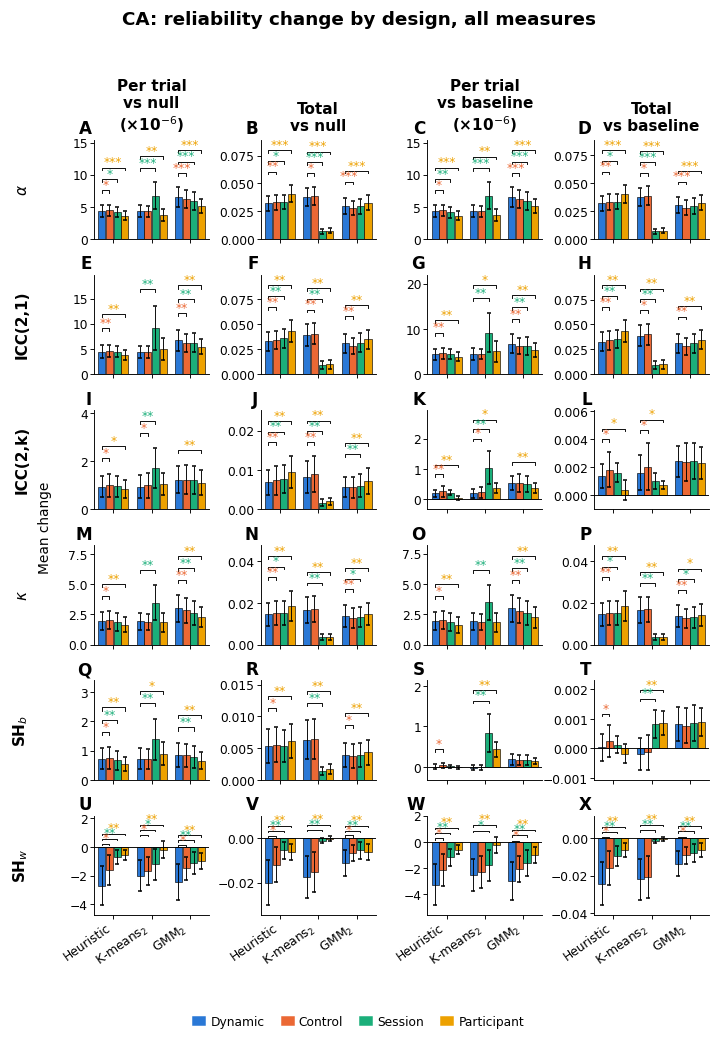

saved -> /home/sjsuss626/EMST_files/sjs_dissertation/dervatives/dynamic_qc/figures/pub_figures/supplement/fig_irr_designs_T3.png (+ fig_irr_designs_T3.json)


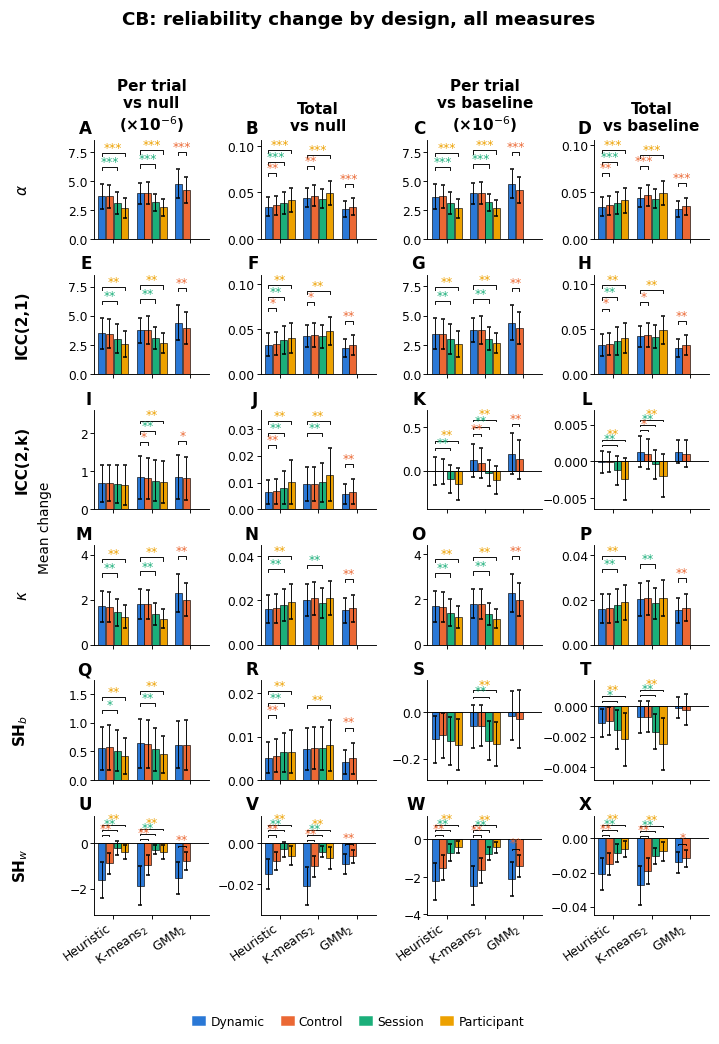

figures: [('supplement', 'fig_decay_curves_raw.png'), ('main_text', 'fig_decay_curves.png'), ('supplement', 'fig_decay_curves_boxcox.png'), ('main_text', 'fig_lvl1_calibration.png'), ('supplement', 'fig_feature_distributions.png'), ('supplement', 'fig_age_by_feature.png'), ('supplement', 'fig_dose_response.png'), ('supplement', 'fig_gmm_posterior.png'), ('supplement/participants', 'fig_participant_4064.png'), ('supplement/participants', 'fig_participant_1051.png'), ('supplement', 'fig_method_agreement.png'), ('supplement', 'fig_sweep_overlap.png'), ('supplement', 'fig_sweep_profiles.png'), ('main_text', 'fig_h3_designs.png'), ('supplement', 'fig_irr_designs_T2.png'), ('supplement', 'fig_irr_designs_T3.png')]


In [13]:
# [cell 14]
# =============================================================================
# H3: EVERY RELIABILITY MEASURE BY DESIGN, ONE FIGURE PER DATASET (supplement)
# =============================================================================
# The LVL_2 runs' Step 9 panels for all six measures (rows) and the four quantities (columns: per trial and total, vs
# the matched null and vs the baseline): bars = mean ± SEM over the scales, brackets = dynamic vs each design (BH q
# within panel), an empty slot = a degenerate design. The behavioural heuristic and both carried solutions.
H3_METRICS = [("Alpha", r"$\alpha$"), ("ICC2_1", "ICC(2,1)"), ("ICC2_k", "ICC(2,k)"), ("Kappa", r"$\kappa$"),
              ("SH_Between", "SH$_b$"), ("SH_Within", "SH$_w$")]
H3_QCOLS = [("Excess per trial", "Per trial\nvs null\n(×10$^{-6}$)"), ("Excess", "Total\nvs null"),
            ("Per trial", "Per trial\nvs baseline\n(×10$^{-6}$)"), ("Improvement", "Total\nvs baseline")]
for rk in H3_RUNS:
    with plt.rc_context(RC_FIG):
        fig, axes = plt.subplots(len(H3_METRICS), len(H3_QCOLS), figsize=(6.5, 9.4))
        fig.subplots_adjust(left=0.13, right=0.99, top=0.87, bottom=0.12, wspace=0.45, hspace=0.36)
        for i, (m, _) in enumerate(H3_METRICS):
            for j, (q, qlab) in enumerate(H3_QCOLS):
                ax = axes[i, j]
                h3_bars(ax, rk, m, q, list(H3_SOL), step_frac=0.2)
                if i == 0:
                    ax.set_title(qlab)
                if i < len(H3_METRICS) - 1:
                    ax.tick_params(labelbottom=False)
                else:
                    plt.setp(ax.get_xticklabels(), rotation=35, ha="right")
                panel_letter(ax, chr(65 + len(H3_QCOLS) * i + j))
        left_headers(fig, axes[:, 0], [lab for _, lab in H3_METRICS], ylabel="Mean change")
        bottom_key(fig, [plt.Rectangle((0, 0), 1, 1, color=H3_DCOL[d]) for d in H3_DESIGNS],
                   [H3_DLAB[d] for d in H3_DESIGNS])
        fig_title(fig, f"{COHORT[rk]}: reliability change by design, all measures")
        save_figure(fig, f"fig_irr_designs_{rk}", "supplement",
                    [f"{RUN[rk]}_{k}.csv" for k in ("step9_design_summary", "step9_design_tests")]
                    + [LVL_OUTS / f"{LVL2_SWEEP}_selection.json"], tight=False)
        plt.show()
print("figures:", FIGURES)
